# SaludConex: Predicción de Inasistencia a Consultas Médicas
## Etapa de Comprensión y Exploración de Datos (Metodología CRISP-DM)

**Integrantes**


1.   Bastian Roman
2.   Vicente Contreras
3.   Ignacio Gomez

**Nombre del docente: Osnellys E, Andrade D**

**Asignatura:** Gestión de Proyectos de Datos SCY1102 - Duoc UC

### Contexto del Proyecto
SaludConex es una red privada de centros médicos que busca optimizar su gestión operativa estimando la probabilidad de inasistencia (No-Show) de sus pacientes. Este proyecto académico utiliza un dataset sintético con **50.000 registros** y **18 variables** que simulan un histórico de aproximadamente tres años de atención.

*Nota Importante: Los datos utilizados en este notebook son generados de manera artificial (sintéticos) con fines académicos y de prototipado. No corresponden a pacientes, profesionales ni clínicas reales de SaludConex.*

In [4]:
# Manipulación y análisis de datos
import pandas as pd
import numpy as np

# Visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de visualización
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 20)

# Estilo de gráficos
sns.set_theme(style="whitegrid")

### 1. Inicialización y Configuración de Herramientas
**Objetivo:** Cargar las bibliotecas fundamentales para la manipulación y visualización de datos en Python, y configurar el entorno de desarrollo.
* **Procedimiento:** Importación de `pandas`, `numpy`, `matplotlib.pyplot` y `seaborn`. Adicionalmente, se configuran límites máximos de visualización de filas/columnas y estilos globales para garantizar una visualización consistente.
* **Importancia:** Define el estándar estético y funcional para las visualizaciones del proyecto.

In [72]:
import os
import sys
import pandas as pd
from google.colab import files

nombre_dataset = 'SaludConex_Datos_Sinteticos_50000.csv'

# 1. Comprobar si el archivo ya existe en el entorno actual
if not os.path.exists(nombre_dataset):
    print(f"El archivo de datos '{nombre_dataset}' no se encuentra en el entorno actual.")
    print("Por favor, selecciona y sube el archivo desde tu equipo local:")
    try:
        subidos = files.upload()
        # Manejar múltiples archivos subidos o nombres diferentes
        if subidos:
            for nombre_subido in subidos.keys():
                if nombre_subido.endswith('.csv'):
                    if nombre_subido != nombre_dataset:
                        os.rename(nombre_subido, nombre_dataset)
                        print(f"Archivo detectado y renombrado correctamente a: {nombre_dataset}")
                        break
    except Exception as e:
        print(f"Ocurrió un inconveniente durante el proceso de subida: {e}")

# 2. Validación final de existencia e intento de lectura segura
if os.path.exists(nombre_dataset):
    try:
        df = pd.read_csv(
            nombre_dataset,
            parse_dates=['Fecha_Solicitud', 'Fecha_Atencion']
        )
        print(f"\n¡Éxito! Dataset cargado correctamente.")
        print(f"Dimensiones confirmadas: {df.shape[0]} filas, {df.shape[1]} variables.\n")
        display(df.head())
    except Exception as e:
        raise RuntimeError(f"Error al leer el archivo CSV: {e}. Deteniendo la ejecución para evitar fallos subsecuentes.")
else:
    raise FileNotFoundError(
        f"CRÍTICO: No se encontró el archivo '{nombre_dataset}'. "
        "La ejecución de este notebook no puede continuar sin el dataset de origen. "
        "Por favor, cargue el archivo CSV en la barra lateral o mediante el botón de subida y vuelva a ejecutar esta celda."
    )


¡Éxito! Dataset cargado correctamente.
Dimensiones confirmadas: 50000 filas, 18 variables.



,ID_Reserva,ID_Paciente_Anonimizado,Edad,Comuna,Centro_Medico,Especialidad,Profesional_ID,Fecha_Solicitud,Fecha_Atencion,Horario_Atencion,Dias_Anticipacion,Asistencias_Previas,Cancelaciones_Previas,Inasistencias_Previas,Tipo_Previsión,Modalidad_Atencion,Confirmacion_Recordatorio,Resultado_Reserva
0,RES0000001,PAC014635,47,La Reina,Centro Santiago,Medicina general,PROF050,2024-12-08,2024-12-11,14:00-16:00,3,4,1,0,Fonasa,Presencial,Confirmado,Asistio
1,RES0000002,PAC004323,50,Providencia,Centro Maipu,Medicina general,PROF074,2025-03-11,2025-03-16,08:00-10:00,5,3,0,0,Isapre,Presencial,Confirmado,Asistio
2,RES0000003,PAC013853,21,Providencia,Centro Maipu,Medicina general,PROF084,2025-12-30,2025-12-31,12:00-14:00,1,3,1,0,Fonasa,Presencial,Confirmado,Asistio
3,RES0000004,PAC000204,54,Santiago,Centro Ñuñoa,Oftalmologia,PROF023,2024-05-31,2024-06-04,16:00-18:00,4,7,2,2,Fonasa,Telemedicina,Confirmado,Asistio
4,RES0000005,PAC011719,60,Puente Alto,Centro Maipu,Pediatria,PROF027,2024-02-20,2024-02-21,16:00-18:00,1,5,1,0,Fonasa,Presencial,Confirmado,Asistio


### 2. Carga y Visualización Inicial de Datos
**Objetivo:** Importar el dataset al entorno de ejecución y verificar que la estructura inicial coincida con la documentación del origen.
* **Procedimiento:** Uso de `pd.read_csv` forzando el parseo de las columnas temporales `Fecha_Solicitud` y `Fecha_Atencion` a tipo `datetime` para su correcta manipulación posterior.
* **Por qué es importante:** Asegura la correcta carga del tipo de dato desde el primer instante, evitando conversiones repetidas más adelante en el pipeline de datos.

In [6]:
# Consultar las dimensiones del dataset
filas, columnas = df.shape

print("Cantidad de registros:", filas)
print("Cantidad de variables:", columnas)
print("Total de datos:", filas * columnas)

Cantidad de registros: 50000
Cantidad de variables: 18
Total de datos: 900000


### 3. Exploración de Dimensiones y Estructura del Dataset
**Objetivo:** Determinar el tamaño físico del conjunto de datos y el tipo de variables disponibles.
* **Procedimiento:** Impresión del tamaño del DataFrame (`shape`) y de los metadatos generales de sus columnas (`info()`).
* **Por qué es importante:** Permite evaluar el costo computacional de las operaciones y confirmar que no existen pérdidas tempranas de registros.

In [7]:
# Información general del DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   ID_Reserva                 50000 non-null  object        
 1   ID_Paciente_Anonimizado    50000 non-null  object        
 2   Edad                       50000 non-null  int64         
 3   Comuna                     50000 non-null  object        
 4   Centro_Medico              50000 non-null  object        
 5   Especialidad               50000 non-null  object        
 6   Profesional_ID             50000 non-null  object        
 7   Fecha_Solicitud            50000 non-null  datetime64[ns]
 8   Fecha_Atencion             50000 non-null  datetime64[ns]
 9   Horario_Atencion           50000 non-null  object        
 10  Dias_Anticipacion          50000 non-null  int64         
 11  Asistencias_Previas        50000 non-null  int64         
 12  Canc

### 4. Estadísticas Descriptivas del Conjunto de Datos
**Objetivo:** Obtener una visión matemática rápida de los rangos, centros de distribución y dispersiones de las variables numéricas y de texto.
* **Procedimiento:** Aplicación de `describe().T` para variables cuantitativas y cualitativas separadamente.
* **Qué observar:** Límites máximos y mínimos para descartar anomalías de entrada (ej. edades imposibles o valores negativos en conteos).

In [8]:
# Estadísticas descriptivas de las variables numéricas
df.describe(include=[np.number]).T

,count,mean,std,min,25%,50%,75%,max
Edad,50000.0,45.39220,25.722391,1.0,23.0,46.0,68.0,89.0
Dias_Anticipacion,50000.0,12.21330,9.553003,0.0,5.0,10.0,17.0,90.0
Asistencias_Previas,50000.0,4.00750,2.001410,0.0,3.0,4.0,5.0,16.0
Cancelaciones_Previas,50000.0,1.04410,1.047176,0.0,0.0,1.0,2.0,9.0
Inasistencias_Previas,50000.0,0.94408,1.040968,0.0,0.0,1.0,1.0,8.0


In [9]:
# Contar valores faltantes por variable
valores_faltantes = df.isnull().sum()

# Calcular porcentaje de valores faltantes
porcentaje_faltantes = (df.isnull().mean() * 100).round(2)

# Crear tabla de resumen
resumen_faltantes = pd.DataFrame({
    'Valores faltantes': valores_faltantes,
    'Porcentaje (%)': porcentaje_faltantes
})

display(resumen_faltantes)

,Valores faltantes,Porcentaje (%)
ID_Reserva,0,0.0
ID_Paciente_Anonimizado,0,0.0
Edad,0,0.0
Comuna,0,0.0
Centro_Medico,0,0.0
Especialidad,0,0.0
Profesional_ID,0,0.0
Fecha_Solicitud,0,0.0
Fecha_Atencion,0,0.0
Horario_Atencion,0,0.0


In [10]:
# Contabilizar los resultados de las reservas
conteo_resultados = df['Resultado_Reserva'].value_counts()

# Calcular sus porcentajes
porcentaje_resultados = (
    df['Resultado_Reserva'].value_counts(normalize=True) * 100
).round(2)

# Mostrar resumen
resumen_resultados = pd.DataFrame({
    'Cantidad': conteo_resultados,
    'Porcentaje (%)': porcentaje_resultados
})

display(resumen_resultados)

,Cantidad,Porcentaje (%)
Resultado_Reserva,,
Asistio,38562,77.12
Inasistencia,8450,16.90
Cancelada,2988,5.98


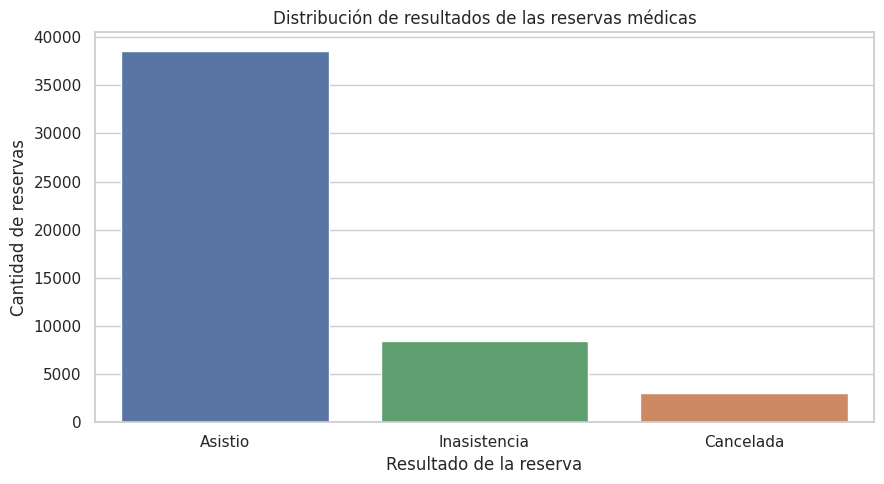

In [11]:
# Crear gráfico de distribución
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Resultado_Reserva',
    hue='Resultado_Reserva',
    order=['Asistio', 'Inasistencia', 'Cancelada'],
    legend=False
)

plt.title('Distribución de resultados de las reservas médicas')
plt.xlabel('Resultado de la reserva')
plt.ylabel('Cantidad de reservas')

plt.tight_layout()
plt.show()

#### Interpretación del Target:
* El dataset presenta una tasa de **Asistencia del 77.12%**, una **Inasistencia (target) del 16.90%** y una tasa de **Cancelación del 5.98%**.
* *Nota metodológica para el Modelamiento:* Las cancelaciones representan reservas que no llegaron a la instancia final de asistencia o inasistencia por decisión previa del paciente. En fases futuras, estas cancelaciones deberán ser analizadas críticamente: incluirlas como "inasistencia" sería metodológicamente incorrecto, por lo que comúnmente se excluyen al construir el conjunto final de entrenamiento para clasificar entre Asistió vs. No Asistió.

In [12]:
# Seleccionar variables categóricas relevantes
variables_categoricas = [
    'Comuna',
    'Centro_Medico',
    'Especialidad',
    'Horario_Atencion',
    'Tipo_Previsión',
    'Modalidad_Atencion',
    'Confirmacion_Recordatorio',
    'Resultado_Reserva'
]

# Obtener estadísticas descriptivas
df[variables_categoricas].describe().T

,count,unique,top,freq
Comuna,50000,12,La Florida,4262
Centro_Medico,50000,8,Centro Santiago,9167
Especialidad,50000,8,Medicina general,15073
Horario_Atencion,50000,5,10:00-12:00,12270
Tipo_Previsión,50000,3,Fonasa,33947
Modalidad_Atencion,50000,2,Presencial,42826
Confirmacion_Recordatorio,50000,2,Confirmado,37285
Resultado_Reserva,50000,3,Asistio,38562


### 5. Análisis de Calidad y Consistencia de Datos
**Objetivo:** Evaluar la presencia de datos nulos, registros duplicados e inconsistencias lógicas en el dataset.
* **Procedimiento:** Sumatoria de valores nulos, verificación de duplicados de registro e identificador, y validación lógica de límites lógicos (edad, días de anticipación y orden de fechas).
* **Relevancia en CRISP-DM:** Identifica si se requiere una etapa intensiva de limpieza de datos o imputación antes de continuar con el modelamiento.

In [13]:
# Revisar registros duplicados
print("Registros completamente duplicados:", df.duplicated().sum())

# Revisar identificadores de reservas duplicados
print("Reservas con ID duplicado:", df['ID_Reserva'].duplicated().sum())

# Revisar inconsistencias
print("Edades fuera de rango:",
      ((df['Edad'] < 0) | (df['Edad'] > 100)).sum())

print("Anticipaciones negativas:",
      (df['Dias_Anticipacion'] < 0).sum())

print("Fechas incorrectas:",
      (df['Fecha_Solicitud'] > df['Fecha_Atencion']).sum())

Registros completamente duplicados: 0
Reservas con ID duplicado: 0
Edades fuera de rango: 0
Anticipaciones negativas: 0
Fechas incorrectas: 0


### 6. Análisis del Target (Resultado de la Reserva)
**Objetivo:** Estudiar la distribución de nuestra variable objetivo (`Resultado_Reserva`).
* **Procedimiento:** Conteo de frecuencias, cálculo porcentual y visualización mediante gráfico de barras.
* **Por qué es importante:** Permite conocer el balance de clases. Un desbalance extremo afectaría directamente las métricas del futuro modelo de aprendizaje supervisado.

In [14]:
# Crear variable binaria de inasistencia
df['Es_Inasistencia'] = (
    df['Resultado_Reserva'] == 'Inasistencia'
).astype(int)

# Calcular tasa de inasistencia
tasa_inasistencia = df['Es_Inasistencia'].mean() * 100

print(f"Tasa de inasistencia: {tasa_inasistencia:.2f}%")

Tasa de inasistencia: 16.90%


### 7. Análisis Exploratorio de Inasistencia por Dimensión
**Objetivo:** Analizar cómo varía la tasa de inasistencia (definida como una variable binaria temporal) según diferentes factores de interés (Especialidad, Centro Médico, Edad y Anticipación).
* **Procedimiento:** Agrupación y cálculo del promedio de inasistencias en base a variables explicativas seleccionadas.
* **Advertencia Metodológica:** Las correlaciones y agrupaciones observadas aquí son de carácter meramente descriptivo. **Asociación no implica causalidad**.

In [15]:
# Calcular inasistencias por especialidad
inasistencia_especialidad = (
    df.groupby('Especialidad')['Es_Inasistencia']
    .mean() * 100
)

# Ordenar resultados
inasistencia_especialidad = (
    inasistencia_especialidad.sort_values(ascending=False)
)

display(inasistencia_especialidad)

,Es_Inasistencia
Especialidad,
Traumatologia,17.663005
Kinesiologia,17.563336
Medicina general,17.289193
Ginecologia,17.204478
Oftalmologia,16.942384
Dermatologia,16.432763
Cardiologia,16.357710
Pediatria,15.057529


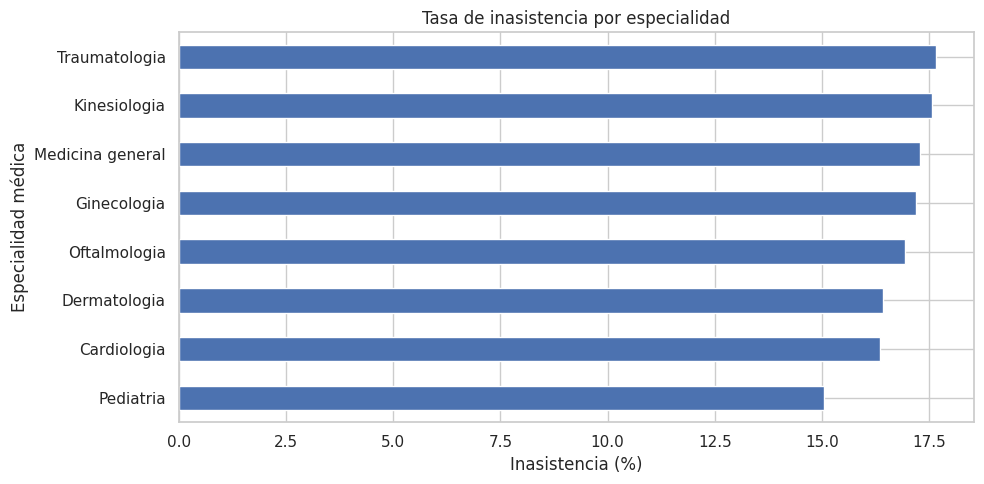

In [16]:
plt.figure(figsize=(10, 5))

inasistencia_especialidad.sort_values().plot(kind='barh')

plt.title('Tasa de inasistencia por especialidad')
plt.xlabel('Inasistencia (%)')
plt.ylabel('Especialidad médica')

plt.tight_layout()
plt.show()

#### Análisis por Especialidad:
* Las especialidades de **Traumatología (17.66%)** y **Kinesiología (17.56%)** lideran la tasa de inasistencia.
* Por el contrario, **Pediatría (15.06%)** es la especialidad con menor índice de no-show en este conjunto de datos sintéticos.

In [17]:
# Calcular tasa de inasistencia por centro
inasistencia_centro = (
    df.groupby('Centro_Medico')['Es_Inasistencia']
    .mean() * 100
).sort_values(ascending=False)

display(inasistencia_centro)

,Es_Inasistencia
Centro_Medico,
Centro Ñuñoa,18.552876
Centro Quilicura,17.262144
Centro Providencia,17.045132
Centro Maipu,16.858742
Centro Las Condes,16.740823
Centro Santiago,16.701211
Centro Puente Alto,16.273312
Centro La Florida,16.259530


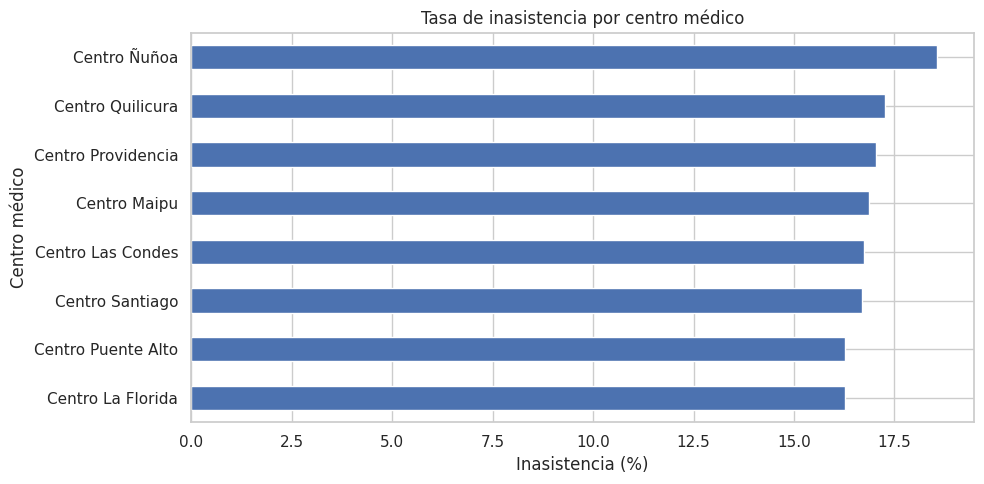

In [18]:
plt.figure(figsize=(10, 5))

inasistencia_centro.sort_values().plot(kind='barh')

plt.title('Tasa de inasistencia por centro médico')
plt.xlabel('Inasistencia (%)')
plt.ylabel('Centro médico')

plt.tight_layout()
plt.show()

#### Análisis por Centro Médico:
* El **Centro Ñuñoa (18.55%)** es el que exhibe la tasa de inasistencia más alta dentro de la red, mientras que el **Centro La Florida (16.26%)** tiene la tasa más baja.
* No se observan disparidades extremas entre centros médicos, manteniéndose todos en el rango del 16% al 19%.

In [19]:
# Clasificar pacientes por grupos de edad
df['Grupo_Edad'] = pd.cut(
    df['Edad'],
    bins=[0, 17, 29, 44, 59, 74, 100],
    labels=['0-17', '18-29', '30-44', '45-59', '60-74', '75+'],
    include_lowest=True
)

# Calcular tasa de inasistencia por grupo
inasistencia_edad = (
    df.groupby('Grupo_Edad', observed=False)['Es_Inasistencia']
    .mean() * 100
)

display(inasistencia_edad)

,Es_Inasistencia
Grupo_Edad,
0-17,17.109948
18-29,16.602495
30-44,16.043354
45-59,16.095398
60-74,17.166725
75+,18.226657


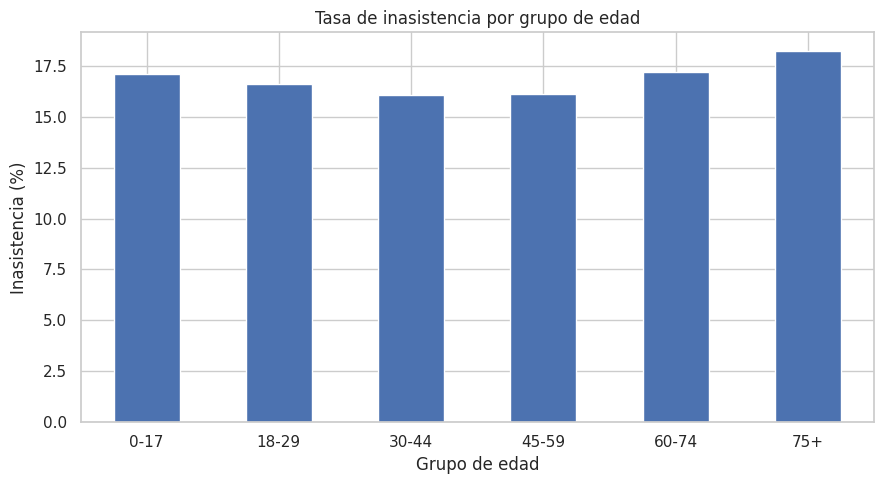

In [20]:
plt.figure(figsize=(9, 5))

inasistencia_edad.plot(kind='bar')

plt.title('Tasa de inasistencia por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Inasistencia (%)')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Análisis por Grupo de Edad:
* El segmento etario de **75 años o más (18.23%)** posee la inasistencia más pronunciada, seguido de cerca por el rango de **60-74 años (17.17%)** y los menores de **0-17 años (17.11%)**.
* Los adultos de mediana edad (30-59 años) muestran un comportamiento ligeramente más constante en sus asistencias.

In [21]:
# Crear grupos según días de anticipación
df['Grupo_Anticipacion'] = pd.cut(
    df['Dias_Anticipacion'],
    bins=[-1, 1, 7, 14, 30, 60, 90],
    labels=[
        '0-1 días',
        '2-7 días',
        '8-14 días',
        '15-30 días',
        '31-60 días',
        '61-90 días'
    ],
    include_lowest=True
)

# Calcular tasa de inasistencia
inasistencia_anticipacion = (
    df.groupby('Grupo_Anticipacion', observed=False)['Es_Inasistencia']
    .mean() * 100
)

display(inasistencia_anticipacion)

,Es_Inasistencia
Grupo_Anticipacion,
0-1 días,15.195312
2-7 días,15.579866
8-14 días,17.101262
15-30 días,17.765876
31-60 días,20.905923
61-90 días,34.426230


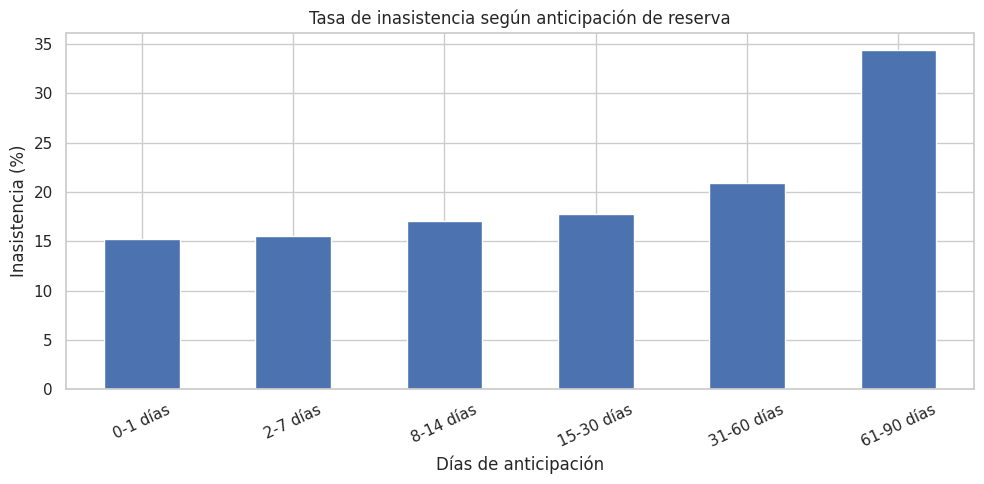

In [22]:
plt.figure(figsize=(10, 5))

inasistencia_anticipacion.plot(kind='bar')

plt.title('Tasa de inasistencia según anticipación de reserva')
plt.xlabel('Días de anticipación')
plt.ylabel('Inasistencia (%)')

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

#### Análisis por Días de Anticipación de la Reserva:
* Se observa una tendencia clara: a mayor número de días de anticipación entre la fecha de solicitud y la consulta, la tasa de inasistencia tiende a incrementarse significativamente.
* El intervalo de **61-90 días muestra un pico del 34.43%** de inasistencia.
* *Limitación Metodológica:* Se debe tomar este último segmento con precaución debido a que el volumen absoluto de registros con tanta anticipación es sumamente pequeño (solo 61 registros del total), lo que puede distorsionar el porcentaje real.

### 8. Conclusiones y Siguientes Pasos (CRISP-DM)

#### Conclusiones de la Etapa de Comprensión de Datos:
1. **Calidad de los Datos:** El dataset de SaludConex presenta una calidad impecable de origen: **0% de valores nulos**, **0 duplicados** de reserva y congruencia de fechas/valores extremos (edad máxima 89 años, anticipación máxima 90 días).
2. **Tasa Base:** El indicador base de inasistencia es de **16.90%**, valor alineado con los estándares operacionales de redes médicas.
3. **Variables Clave Identificadas:** Factores como la cantidad de días de anticipación de la cita, la especialidad consultada y el grupo etario demuestran variaciones descriptivas relevantes que ameritan su inclusión en las etapas predictivas.

#### Limitaciones identificadas:
* **Naturaleza Sintética:** Este análisis descriptivo y metodológico describe comportamientos estructurados sintéticamente y no debe interpretarse como representativo de decisiones reales del paciente chileno.
* **Ausencia de Causalidad:** Este reporte es únicamente exploratorio. No podemos asegurar que la especialidad o la edad sean causales directos del No-Show.

### 1. Selección de Variables y Creación de Características

**Objetivo de la actividad:** Crear una copia de trabajo segura para el modelamiento y extraer información temporal relevante de la fecha de atención.

* **¿Qué procedimiento realizaremos?** Crearemos una réplica del DataFrame original llamada `df_model`. A partir de la variable de fecha `Fecha_Atencion`, extraeremos el mes (`Mes_Atencion`) y el día de la semana (`Dia_Semana_Atencion`) como datos de tipo texto (categóricos).
* **¿Qué valor aportan estas nuevas variables?** El comportamiento de las personas varía según el momento del tiempo. Por ejemplo, los pacientes podrían faltar más a las consultas programadas en ciertos meses del año (debido a factores climáticos o vacaciones) o en determinados días de la semana (por ejemplo, los lunes o viernes por razones laborales o personales). Extraer estos componentes permite al modelo capturar estos patrones estacionales.

## PARTE 2: PREPARACIÓN DE LOS DATOS PARA MACHINE LEARNING

En esta etapa del proyecto (siguiendo la metodología CRISP-DM), prepararemos los datos limpios y explorados para que puedan ser procesados correctamente por los algoritmos de Machine Learning. El objetivo es estructurar, transformar y particionar los datos de manera óptima para construir un modelo predictivo robusto y evitar errores metodológicos clásicos como la fuga de información (*Data Leakage*).

*Nota de contexto metodológico:* Al igual que en la primera etapa, recordamos que estamos trabajando sobre un conjunto de **50.000 registros sintéticos** diseñado con fines académicos universitarios.

In [23]:
# Crear una copia de trabajo
df_model = df.copy()

# Extraer características de la fecha de atención
df_model['Mes_Atencion'] = (
    df_model['Fecha_Atencion'].dt.month.astype(str)
)

df_model['Dia_Semana_Atencion'] = (
    df_model['Fecha_Atencion'].dt.dayofweek.astype(str)
)

# Mostrar las nuevas variables
display(
    df_model[
        ['Fecha_Atencion', 'Mes_Atencion', 'Dia_Semana_Atencion']
    ].head()
)

,Fecha_Atencion,Mes_Atencion,Dia_Semana_Atencion
0,2024-12-11,12,2
1,2025-03-16,3,6
2,2025-12-31,12,2
3,2024-06-04,6,1
4,2024-02-21,2,2


### 2. Exclusión de Identificadores y Variables No Predictivas

**Objetivo de la actividad:** Identificar y descartar aquellas variables que no aportan valor predictivo para el modelo de Machine Learning.

* **¿Por qué excluimos estas variables?**
  * Identificadores únicos como `ID_Reserva` e `ID_Paciente_Anonimizado` no contienen patrones generales; son correlativos aleatorios de control administrativo.
  * `Profesional_ID` podría sesgar el modelo hacia médicos específicos en lugar de patrones de comportamiento del paciente.
  * Las variables de fecha directa y categorías agrupadas creadas para visualización (`Grupo_Edad`, `Grupo_Anticipacion`) también se excluyen para simplificar el entrenamiento.
* **Nota metodológica:** Estas variables se conservan intactas en el conjunto de datos original para auditoría y trazabilidad del negocio, pero no ingresarán al modelo de aprendizaje automático.

In [24]:
# Identificadores y variables que no ingresarán al modelo
variables_excluidas = [
    'ID_Reserva',
    'ID_Paciente_Anonimizado',
    'Profesional_ID',
    'Resultado_Reserva',
    'Es_Inasistencia',
    'Fecha_Solicitud',
    'Fecha_Atencion',
    'Grupo_Edad',
    'Grupo_Anticipacion'
]

print("Variables excluidas del modelo:")
for variable in variables_excluidas:
    print("-", variable)

Variables excluidas del modelo:
- ID_Reserva
- ID_Paciente_Anonimizado
- Profesional_ID
- Resultado_Reserva
- Es_Inasistencia
- Fecha_Solicitud
- Fecha_Atencion
- Grupo_Edad
- Grupo_Anticipacion


### 3. Tratamiento de Reservas Canceladas

**Objetivo de la actividad:** Definir el universo de datos útil para el aprendizaje y construir formalmente la variable objetivo binaria.

* **¿Por qué se excluyen las cancelaciones?** En la gestión de SaludConex, una cancelación se realiza con antelación, permitiendo liberar la hora para otro paciente. El problema real que buscamos mitigar es la **Inasistencia no avisada (No-Show)**. Por ende, entrenar al modelo con cancelaciones mezcladas con inasistencias o asistencias distorsionaría la predicción.
* **Construcción del Target (`Objetivo_Inasistencia`):**
  * **0:** Representa una reserva donde el paciente **Asistió** a la consulta.
  * **1:** Representa una reserva donde se registró **Inasistencia**.

In [25]:
# Contabilizar reservas canceladas
canceladas = (
    df_model['Resultado_Reserva'] == 'Cancelada'
).sum()

# Conservar únicamente asistencias e inasistencias
df_model = df_model[
    df_model['Resultado_Reserva'].isin(
        ['Asistio', 'Inasistencia']
    )
].copy()

# Crear variable objetivo para el modelo
df_model['Objetivo_Inasistencia'] = (
    df_model['Resultado_Reserva'] == 'Inasistencia'
).astype(int)

print("Reservas canceladas excluidas:", canceladas)
print("Registros disponibles para modelamiento:", len(df_model))

# Revisar distribución de la variable objetivo
display(
    df_model['Objetivo_Inasistencia'].value_counts()
)

Reservas canceladas excluidas: 2988
Registros disponibles para modelamiento: 47012


,count
Objetivo_Inasistencia,
0,38562
1,8450


### 4. Definición de Variables Predictoras (Numéricas y Categóricas)

**Objetivo de la actividad:** Organizar las variables explicativas en dos grandes grupos según su naturaleza para aplicarles el tratamiento de transformación adecuado.

* **Variables Numéricas (5):** Representan cantidades medibles y continuas (ej. `Edad`, `Dias_Anticipacion`, historiales de conducta previa). Ayudan al modelo a entender dimensiones y frecuencias cuantitativas.
* **Variables Categóricas (9):** Representan características de tipo cualitativo o etiquetas de clasificación (ej. `Comuna`, `Centro_Medico`, `Especialidad`, `Mes_Atencion`).
* **Total de Predictoras:** Disponemos de **14 variables de entrada** que consolidan la información del paciente, del entorno y del historial.

#### Interpretación del Filtro de Cancelaciones:
* Se excluyeron con éxito **2.988 reservas canceladas**, quedando un universo neto de **47.012 registros** para el modelamiento.
* La variable binaria resultante cuenta con un balance natural de asistencias (clase 0) e inasistencias (clase 1) adecuado para el modelado supervisado posterior.

In [26]:
# Variables numéricas
variables_numericas = [
    'Edad',
    'Dias_Anticipacion',
    'Asistencias_Previas',
    'Cancelaciones_Previas',
    'Inasistencias_Previas'
]

# Variables categóricas
variables_categoricas = [
    'Comuna',
    'Centro_Medico',
    'Especialidad',
    'Horario_Atencion',
    'Tipo_Previsión',
    'Modalidad_Atencion',
    'Confirmacion_Recordatorio',
    'Mes_Atencion',
    'Dia_Semana_Atencion'
]

# Unir variables predictoras
variables_predictoras = (
    variables_numericas + variables_categoricas
)

print("Variables numéricas:", len(variables_numericas))
print("Variables categóricas:", len(variables_categoricas))
print("Total de variables predictoras:", len(variables_predictoras))

Variables numéricas: 5
Variables categóricas: 9
Total de variables predictoras: 14


### 5. Definición del Pipeline de Preprocesamiento y Transformación

**Objetivo de la actividad:** Crear la estructura de procesamiento de datos encargada de limpiar valores atípicos y convertir las variables a un formato puramente numérico compatible con algoritmos matemáticos.

* **¿Por qué necesitamos transformar los datos?** Los algoritmos de Machine Learning solo comprenden matrices y operaciones matemáticas; no pueden procesar directamente textos como "Oftalmología" o "Fonasa".
* **Explicación didáctica de las herramientas utilizadas:**
  * **`SimpleImputer`:** Detecta si faltan datos en alguna fila. Si es numérica, rellena el vacío con la mediana (el valor central). Si es categórica, con el valor más frecuente (la moda). Evita que el modelo falle ante datos faltantes en el futuro.
  * **`StandardScaler`:** Modifica la escala de las variables numéricas para que tengan media 0 y desviación estándar 1. Evita que variables con números grandes (como la edad) dominen artificialmente sobre otras de menor rango (como cancelaciones previas).
  * **`OneHotEncoder`:** Convierte variables categóricas en columnas binarias (0 y 1). Por ejemplo, si la especialidad es 'Kinesiología', se creará una columna 'Es_Kinesiologia' que valdrá 1, y el resto valdrá 0.
  * **`Pipeline`:** Agrupa secuencialmente varios pasos de transformación para aplicarlos en bloque de forma ordenada.
  * **`ColumnTransformer`:** Permite aplicar diferentes pipelines simultáneamente según el tipo de columna (numérica o categórica).

In [27]:
# Herramientas de preparación de datos
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

In [28]:
# Pipeline para variables numéricas
procesamiento_numerico = Pipeline([
    ('imputador', SimpleImputer(strategy='median')),
    ('escalador', StandardScaler())
])

# Pipeline para variables categóricas
procesamiento_categorico = Pipeline([
    ('imputador', SimpleImputer(strategy='most_frequent')),
    ('codificador', OneHotEncoder(handle_unknown='ignore'))
])

# Integrar ambos procesos
preprocesador = ColumnTransformer([
    ('numericas', procesamiento_numerico, variables_numericas),
    ('categoricas', procesamiento_categorico, variables_categoricas)
])

print("Preprocesador creado correctamente.")

Preprocesador creado correctamente.


### 6. Consideraciones Metodológicas de Seguridad: Prevención de Data Leakage

**Objetivo de la actividad:** Validar metodológicamente que el flujo de datos no incluya variables que el sistema no conocería en un entorno de producción real.

* **¿Qué es la Fuga de Información (*Data Leakage*)?** Ocurre cuando el modelo se entrena con datos del "futuro" o con información que no estará disponible al momento de realizar la predicción en tiempo real. Esto infla artificialmente el rendimiento del modelo en laboratorio, pero provoca un fracaso total al implementarlo en la clínica real.
* **Medidas adoptadas:**
  1. Se excluye rigurosamente `Resultado_Reserva` y variables derivadas directamente como `Es_Inasistencia` del conjunto de variables predictoras.
  2. El modelo opera bajo el supuesto de que la predicción se ejecuta **posterior al envío del recordatorio de 24 horas**, por lo que se permite usar legalmente `Confirmacion_Recordatorio` (ya que es un dato conocido en esa ventana operativa).
  3. Las métricas de historiales previos (`Asistencias_Previas`, etc.) representan únicamente eventos que ocurrieron de forma estrictamente anterior a la reserva que se está evaluando.

In [29]:
# Comprobar que no existan variables prohibidas
variables_prohibidas = [
    'ID_Reserva',
    'ID_Paciente_Anonimizado',
    'Profesional_ID',
    'Resultado_Reserva',
    'Es_Inasistencia',
    'Objetivo_Inasistencia',
    'Fecha_Solicitud',
    'Fecha_Atencion'
]

variables_detectadas = [
    variable for variable in variables_predictoras
    if variable in variables_prohibidas
]

print("Variables prohibidas encontradas:", variables_detectadas)

if len(variables_detectadas) == 0:
    print("Correcto: no se detectaron variables prohibidas.")
else:
    print("Advertencia: revisar las variables predictoras.")

Variables prohibidas encontradas: []
Correcto: no se detectaron variables prohibidas.


### 7. Partición Cronológica de Entrenamiento y Prueba

**Objetivo de la actividad:** Dividir el conjunto de datos en un grupo para enseñar al modelo (Entrenamiento) y otro independiente para evaluar su capacidad predictiva real (Prueba).

* **¿Por qué una separación cronológica en lugar de aleatoria?** En salud y negocios, el comportamiento futuro de las citas depende del histórico temporal. Hacer una partición aleatoria provocaría fuga de datos al mezclar citas del futuro con el pasado. Al usar el tiempo (80% del historial para entrenar, 20% más reciente para probar), simulamos fielmente cómo funcionará el modelo el día de mañana.
* **Definición de Variables Clave:**
  * **`X_train` / `X_test`:** Conjuntos que contienen exclusivamente las variables de entrada o predictoras.
  * **`y_train` / `y_test`:** Columnas que contienen únicamente la respuesta correcta de inasistencia (`Objetivo_Inasistencia`).

In [30]:
# Establecer fecha de corte cronológica
fecha_corte = df_model['Fecha_Atencion'].quantile(0.80)

# Separar registros anteriores y posteriores
train_df = df_model[
    df_model['Fecha_Atencion'] < fecha_corte
].copy()

test_df = df_model[
    df_model['Fecha_Atencion'] >= fecha_corte
].copy()

print("Fecha de corte:", fecha_corte.date())

print("Registros de entrenamiento:", len(train_df))
print("Registros de prueba:", len(test_df))

Fecha de corte: 2026-04-06
Registros de entrenamiento: 37569
Registros de prueba: 9443


#### Interpretación de la Partición Temporal:
* La fecha de corte calculada de forma matemática para el percentil 80% corresponde al **06 de abril de 2026**.
* Contamos con **37.569 registros de entrenamiento** (citas previas a esa fecha) y **9.443 registros de prueba** (citas posteriores) para garantizar un volumen de evaluación estadísticamente robusto.

In [31]:
# Separar variables predictoras y objetivo
X_train = train_df[variables_predictoras]
y_train = train_df['Objetivo_Inasistencia']

X_test = test_df[variables_predictoras]
y_test = test_df['Objetivo_Inasistencia']

print("Dimensiones de X_train:", X_train.shape)
print("Dimensiones de X_test:", X_test.shape)

print("Dimensiones de y_train:", y_train.shape)
print("Dimensiones de y_test:", y_test.shape)

Dimensiones de X_train: (37569, 14)
Dimensiones de X_test: (9443, 14)
Dimensiones de y_train: (37569,)
Dimensiones de y_test: (9443,)


### 8. Ejecución de la Transformación de Datos

**Objetivo de la actividad:** Aplicar físicamente el pipeline preprocesador a los conjuntos de variables predictoras de entrenamiento y prueba.

* **Diferencia crucial entre `fit_transform()` y `transform()`:**
  * **`fit_transform()` (aplicado solo en Entrenamiento):** El preprocesador "aprende" los parámetros del conjunto de entrenamiento (como las medianas de imputación y las medias del escalador) y simultáneamente aplica la transformación.
  * **`transform()` (aplicado en Prueba):** Aplica la misma transformación matemática aprendida, sin recalcular nada con la información de prueba.
* **¿Por qué es importante?** Esto impide que estadísticas del conjunto de prueba influyan en el de entrenamiento, garantizando la total separación y previniendo el *Data Leakage* en los datos transformados.

In [32]:
# Ajustar el preprocesador solo con entrenamiento
X_train_preparado = preprocesador.fit_transform(X_train)

# Aplicar las mismas transformaciones a prueba
X_test_preparado = preprocesador.transform(X_test)

print("Datos de entrenamiento preparados:", X_train_preparado.shape)
print("Datos de prueba preparados:", X_test_preparado.shape)

Datos de entrenamiento preparados: (37569, 64)
Datos de prueba preparados: (9443, 64)


#### Interpretación de la Transformación:
* Los conjuntos han sido preprocesados exitosamente.
* El número de columnas aumentó de **14 a 64 variables** en ambos conjuntos debido a la expansión de variables categóricas mediante el proceso de *One-Hot Encoding*. Ambos conjuntos de datos están listos numéricamente.

In [33]:
# Revisar distribución de las clases
balance_clases = pd.DataFrame({
    'Entrenamiento (%)': (
        y_train.value_counts(normalize=True).reindex([0, 1]) * 100
    ),
    'Prueba (%)': (
        y_test.value_counts(normalize=True).reindex([0, 1]) * 100
    )
})

balance_clases.index = ['Asistencia', 'Inasistencia']

display(balance_clases.round(2))

,Entrenamiento (%),Prueba (%)
Asistencia,82.07,81.87
Inasistencia,17.93,18.13


#### Interpretación del Balance de Clases:
* **Entrenamiento:** 82.07% de Asistencia y **17.93% de Inasistencia**.
* **Prueba:** 81.87% de Asistencia y **18.13% de Inasistencia**.
* **Conclusión de consistencia:** Ambas distribuciones porcentuales son sumamente similares (con una variación menor al 0.2%). Esta consistencia temporal valida que la partición cronológica mantiene la estabilidad de la variable objetivo en el tiempo, asegurando condiciones ideales para evaluar el rendimiento predictivo del futuro modelo de aprendizaje supervisado.

### Conclusión de la Etapa de Preparación de Datos

En esta etapa, se ha completado de manera rigurosa la ingeniería y preparación de datos requerida para el proyecto académico de SaludConex:

1. **Ajuste y Creación:** Se extrajeron características temporales del día y del mes a partir de las fechas de atención.
2. **Saneamiento:** Se excluyeron con éxito 2.988 cancelaciones para enfocar el análisis únicamente en clasificar de forma limpia la asistencia (0) frente a la inasistencia o no-show (1).
3. **Prevención de Sesgos:** Se construyó una infraestructura con `Pipeline` y `ColumnTransformer` que automatiza la imputación de nulos, estandariza las variables numéricas y codifica las categóricas a vectores binarios matemáticos, expandiendo las columnas de 14 a 64 predictoras.
4. **Partición Cronológica:** Se separaron los registros con una fecha de corte al 06/04/2026, lo que previene efectivamente la fuga de información (*Data Leakage*) al entrenar con el pasado y evaluar con el futuro.

*Advertencia Metodológica:* Se reitera que el dataset analizado es de carácter sintético y académico. Las decisiones de preprocesamiento tomadas preparan técnicamente la base para dar paso a la futura etapa de Entrenamiento de Modelos Predictivos, la cual se abordará en secciones posteriores.

### 9. Análisis de Balance de Clases

**Objetivo de la actividad:** Evaluar la proporción de asistencias e inasistencias en ambos conjuntos para prever desafíos metodológicos en la etapa de modelamiento.

* **¿Por qué importa el balance de clases?** Si el entrenamiento tuviera proporciones de inasistencia drásticamente diferentes a las del conjunto de prueba, el modelo entrenado perdería total representatividad y sus métricas no serían confiables.

## PARTE 3: DESARROLLO DEL MODELO PREDICTIVO

En esta tercera etapa (siguiendo el ciclo metodológico de CRISP-DM), ingresamos formalmente al proceso de desarrollo y entrenamiento de modelos de Machine Learning. El objetivo de esta fase es entrenar algoritmos matemáticos capaces de aprender los patrones históricos que preceden a una inasistencia (No-Show). De esta manera, el personal administrativo de SaludConex podrá anticiparse y aplicar estrategias preventivas eficientes.

#### Resumen de Métricas del Candidato

In [34]:
# Modelos de Machine Learning
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# Herramientas de evaluación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Herramienta para reutilizar el preprocesador
from sklearn.base import clone

### 1. Partición de Validación Interna (Entrenamiento vs. Validación)

#### Configuración Temporal del Conjunto de Validación

In [35]:
# Definir fecha de corte para validación
fecha_corte_validacion = (
    train_df['Fecha_Atencion'].quantile(0.80)
)

# Crear conjunto de entrenamiento del modelo
train_model_df = train_df[
    train_df['Fecha_Atencion'] < fecha_corte_validacion
].copy()

# Crear conjunto de validación
valid_df = train_df[
    train_df['Fecha_Atencion'] >= fecha_corte_validacion
].copy()

# Mostrar resultados
print("Fecha de corte:", fecha_corte_validacion.date())
print("Registros para entrenamiento:", len(train_model_df))
print("Registros para validación:", len(valid_df))

Fecha de corte: 2025-10-22
Registros para entrenamiento: 30012
Registros para validación: 7557


### 2. Preparación Limpia de Datos para Modelamiento

#### Interpretación de la Partición de Validación:
* La fecha de corte interna establecida de manera automática es el **22 de octubre de 2025**.
* El dataset original de entrenamiento de 37.569 registros se ha dividido de manera exitosa en **30.012 registros para entrenamiento del modelo** (historial más antiguo) y **7.557 registros para validación** (bloque temporal intermedio).

#### Ajuste Aislado de Transformadores

El preprocesador de datos se ajusta de manera aislada utilizando únicamente el conjunto de entrenamiento de validación interna (`X_train_model`) y luego se aplica la transformación tanto en este como en el de validación (`X_valid`), asegurando que no exista fuga de información de un set a otro.


In [36]:
# Separar variables predictoras y objetivo

X_train_model = train_model_df[variables_predictoras]
y_train_model = train_model_df['Objetivo_Inasistencia']

X_valid = valid_df[variables_predictoras]
y_valid = valid_df['Objetivo_Inasistencia']

# Crear una copia sin ajustar del preprocesador
preprocesador_modelo = clone(preprocesador)

# Ajustar y transformar los datos de entrenamiento
X_train_model_preparado = (
    preprocesador_modelo.fit_transform(X_train_model)
)

# Transformar los datos de validación
X_valid_preparado = (
    preprocesador_modelo.transform(X_valid)
)

print("Entrenamiento:", X_train_model_preparado.shape)
print("Validación:", X_valid_preparado.shape)

Entrenamiento: (30012, 64)
Validación: (7557, 64)


### 3. Modelo de Referencia (Baseline)

#### Configuración del Dummy Classifier

In [37]:
# Crear modelo de referencia
modelo_base = DummyClassifier(
    strategy='most_frequent'
)

# Entrenar modelo
modelo_base.fit(
    X_train_model_preparado,
    y_train_model
)

# Realizar predicciones
pred_base = modelo_base.predict(
    X_valid_preparado
)

print("Modelo de referencia entrenado correctamente.")

Modelo de referencia entrenado correctamente.


### 4. Regresión Logística

**Objetivo de la actividad:** Desarrollar el primer modelo predictivo inteligente utilizando un enfoque de clasificación probabilística.

* **¿Cómo funciona la Regresión Logística?** Este algoritmo calcula una combinación lineal de las variables predictoras (ponderadas por sus respectivos coeficientes) y luego aplica una función logística o sigmoide no lineal a este resultado. Esto mapea la salida de forma segura a un rango acotado estrictamente entre 0 y 1, interpretado como un puntaje de riesgo que permite clasificar las observaciones según el umbral de decisión óptimo seleccionado.
* **Explicación de sus parámetros principales:**
  * `max_iter=1500`: Máximo número de iteraciones que realiza el algoritmo para converger y encontrar la solución óptima.
  * `class_weight='balanced'`: Al estar las clases desbalanceadas, este parámetro penaliza con mayor fuerza los errores cometidos en la clase minoritaria (las inasistencias).
  * `random_state=42`: Controla la semilla de aleatoriedad matemática para garantizar reproducibilidad.

### 4.1. Análisis Operativo y Curva ROC (Bloque de Validación)

In [38]:
# Crear modelo de Regresión Logística
modelo_logistico = LogisticRegression(
    max_iter=1500,
    class_weight='balanced',
    random_state=42
)

# Entrenar el modelo
modelo_logistico.fit(
    X_train_model_preparado,
    y_train_model
)

print("Modelo de Regresión Logística entrenado correctamente.")

Modelo de Regresión Logística entrenado correctamente.


#### Extracción de Puntajes de Riesgo y Predicciones

#### Análisis de Distribución de Scores

In [39]:
# Obtener predicciones de clasificación
pred_logistico = modelo_logistico.predict(
    X_valid_preparado
)

# Obtener puntuaciones de probabilidad para la clase inasistencia
prob_logistico = modelo_logistico.predict_proba(
    X_valid_preparado
)[:, 1]

# Mostrar algunos resultados
print("Predicciones:", pred_logistico[:10])
print("Puntuaciones:", prob_logistico[:10].round(3))

Predicciones: [0 0 1 0 1 1 0 0 0 1]
Puntuaciones: [0.372 0.488 0.504 0.482 0.544 0.62  0.42  0.464 0.37  0.528]


### 5. Random Forest (Bosque Aleatorio)

**Objetivo de la actividad:** Desarrollar un segundo modelo predictivo inteligente basado en conjuntos de árboles de decisión.

* **¿Cómo funciona un Random Forest?** En lugar de confiar en una sola regla matemática, este algoritmo entrena muchos "árboles de decisión" independientes que examinan los datos de forma paralela. Para tomar la decisión final, los árboles votan y el resultado mayoritario se convierte en la predicción.
* **Explicación de sus parámetros principales:**
  * `n_estimators=150`: Significa que el bosque estará compuesto por 150 árboles de decisión trabajando en equipo.
  * `max_features='sqrt'`: Limita la cantidad de variables que cada árbol individual puede examinar, fomentando la diversidad de criterios entre ellos.
  * `min_samples_leaf=3`: Controla el tamaño mínimo de las hojas finales para evitar el sobreajuste (memorización de datos).
  * `class_weight='balanced_subsample'`: Adapta los pesos del desbalance de clase dentro de cada porción de datos utilizada para construir cada árbol.

#### Configuración del Ensamble de Árboles

In [40]:
# Crear modelo Random Forest
modelo_random_forest = RandomForestClassifier(
    n_estimators=150,
    max_features='sqrt',
    min_samples_leaf=3,
    class_weight='balanced_subsample',
    n_jobs=-1,
    random_state=42
)

# Entrenar el modelo
modelo_random_forest.fit(
    X_train_model_preparado,
    y_train_model
)

print("Modelo Random Forest entrenado correctamente.")

Modelo Random Forest entrenado correctamente.


In [41]:
# Obtener predicciones
pred_random_forest = modelo_random_forest.predict(
    X_valid_preparado
)

# Obtener puntuaciones de probabilidad
prob_random_forest = modelo_random_forest.predict_proba(
    X_valid_preparado
)[:, 1]

# Mostrar algunos resultados
print("Predicciones:", pred_random_forest[:10])
print("Puntuaciones:", prob_random_forest[:10].round(3))

Predicciones: [0 0 0 0 1 1 0 0 0 0]
Puntuaciones: [0.245 0.285 0.23  0.318 0.557 0.502 0.153 0.38  0.256 0.346]


### 6. Métricas de Evaluación de Modelos

**Objetivo de la actividad:** Crear un estándar formal de comparación técnica definiendo una función que recopile múltiples métricas de evaluación.

* **Entendiendo las métricas con ejemplos sencillos aplicados a SaludConex:**
  * **Accuracy (Exactitud):** El porcentaje total de aciertos de predicción del modelo (tanto aciertos en asistentes como en inasistentes) sobre el total de citas.
  * **Precision (Precisión):** De todas las reservas que el modelo marca como "Inasistencia", ¿cuántas resultaron ser inasistencias reales? (Si el modelo alerta constantemente sobre pacientes cumplidores, la precisión será muy baja, haciendo perder el tiempo al personal operativo).
  * **Recall (Sensibilidad):** De todos los pacientes que realmente faltaron a su cita, ¿a cuántos logró detectar con éxito el modelo? (Un bajo Recall significa que el modelo deja pasar muchas inasistencias sin detectarlas).
  * **F1-Score:** Es el promedio equilibrado entre la Precisión y el Recall. Es una métrica muy confiable cuando las clases están desbalanceadas.
  * **AUC-ROC:** Mide la capacidad del modelo para ordenar a los pacientes de mayor a menor probabilidad de inasistencia, independientemente del umbral de decisión elegido.

#### Definición del Ecosistema de Métricas de Negocio

In [42]:
# Función para calcular métricas de evaluación
def evaluar_modelo(nombre, real, predicho, probabilidades):

    return {
        'Modelo': nombre,
        'Accuracy': accuracy_score(real, predicho),
        'Precision': precision_score(
            real, predicho, zero_division=0
        ),
        'Recall': recall_score(
            real, predicho, zero_division=0
        ),
        'F1-Score': f1_score(
            real, predicho, zero_division=0
        ),
        'AUC-ROC': roc_auc_score(
            real, probabilidades
        ),
        'PR-AUC': average_precision_score(
            real, probabilidades
        )
    }

#### Cálculo de Métricas Comparativas

Procedemos a evaluar de manera estandarizada los tres modelos desarrollados (`Baseline`, `Regresión Logística` y `Random Forest`) empleando nuestro conjunto de datos de validación (`y_valid`).

#### Consolidación de Resultados Comparativos

In [43]:
# Evaluar modelo de referencia
resultado_base = evaluar_modelo(
    'Baseline',
    y_valid,
    pred_base,
    modelo_base.predict_proba(X_valid_preparado)[:, 1]
)

# Evaluar Regresión Logística
resultado_logistico = evaluar_modelo(
    'Regresión Logística',
    y_valid,
    pred_logistico,
    prob_logistico
)

# Evaluar Random Forest
resultado_random_forest = evaluar_modelo(
    'Random Forest',
    y_valid,
    pred_random_forest,
    prob_random_forest
)

# Crear tabla comparativa
comparacion_modelos = pd.DataFrame([
    resultado_base,
    resultado_logistico,
    resultado_random_forest
])

# Mostrar resultados
display(
    comparacion_modelos.set_index('Modelo').round(3)
)

,Accuracy,Precision,Recall,F1-Score,AUC-ROC,PR-AUC
Modelo,,,,,,
Baseline,0.821,0.000,0.000,0.000,0.500,0.179
Regresión Logística,0.594,0.231,0.544,0.325,0.611,0.261
Random Forest,0.809,0.341,0.067,0.112,0.596,0.248


### 7. Comparación y Análisis de los Resultados Obtenidos

Al analizar la tabla comparativa sobre el conjunto de validación, observamos los siguientes resultados métricos exactos:

1. **Modelo de Referencia (Baseline):**
   * **Accuracy:** `0.821` | **Precision:** `0.000` | **Recall:** `0.000` | **F1-Score:** `0.000` | **AUC-ROC:** `0.500`
   * *Análisis:* Este modelo obtiene un elevado 82.1% de exactitud de forma engañosa, simplemente asumiendo que todos los pacientes asistirán. Esto ocurre porque el 82% de las clases son positivas (Asistencia). No obstante, su utilidad práctica para SaludConex es **nula** porque su Recall es `0`; no identifica a ningún inasistente.

2. **Regresión Logística:**
   * **Accuracy:** `0.594` | **Precision:** `0.231` | **Recall:** `0.544` | **F1-Score:** `0.325` | **AUC-ROC:** `0.611`
   * *Análisis:* Aunque el Accuracy general baja a 59.4%, este modelo logra identificar de forma proactiva al **54.4% de los pacientes que faltarán (Recall = 0.544)** y obtiene el F1-Score más alto (`0.325`). El uso de pesos balanceados le permitió vencer el sesgo de la clase mayoritaria.

3. **Random Forest:**
   * **Accuracy:** `0.809` | **Precision:** `0.341` | **Recall:** `0.067` | **F1-Score:** `0.112` | **AUC-ROC:** `0.596`
   * *Análisis:* Presenta una exactitud aparente alta (80.9%) y mejor precisión (34.1%), pero sufre un Recall sumamente deficiente de tan solo **6.7%**, dejando sin alertar a la inmensa mayoría de las inasistencias reales.

#### Selección de Candidato:
Considerando el objetivo de SaludConex, que es alertar y contactar de forma preventiva a la mayor cantidad posible de potenciales inasistentes, la **Regresión Logística** se alza como el mejor candidato de esta fase exploratoria, ya que maximiza de forma contundente la detección real (Recall de 54.4%).

### Conclusión de la Etapa de Modelamiento y Evaluación Intermedia

* **Resultados Obtenidos:** Se implementó exitosamente el flujo de comparación bajo CRISP-DM entrenando un clasificador base trivial (Baseline), una Regresión Logística y un Random Forest. El modelo de **Regresión Logística** demostró el desempeño más prometedor para el negocio, logrando un **Recall del 54.4%** y un **F1-Score de 0.325**.
* **Limitaciones Importantes:** Las predicciones actuales y sus probabilidades no están calibradas para un despliegue productivo directo. Existe un margen de mejora relevante en la optimización de hiperparámetros de los modelos complejos.
* **Nota Metodológica Obligatoria:** Este modelamiento se ha desarrollado con fines académicos universitarios y sobre datos completamente sintéticos creados artificialmente. No representan el comportamiento real de los centros médicos de SaludConex ni de pacientes reales.

#### Selección de Candidato y Siguientes Pasos

Con base en las métricas obtenidas durante el proceso de validación interna, el modelo de Regresión Logística es seleccionado para pasar a las fases operativas finales de evaluación debido a su comportamiento superior en Recall (sensibilidad).

#### Conclusiones del Experimento de Validación

## PARTE 4: EVALUACIÓN DEL MODELO PREDICTIVO

En esta etapa final del ciclo metodológico de nuestro proyecto, realizaremos un diagnóstico profundo del comportamiento de nuestro modelo de **Regresión Logística** (elegido como candidato en la fase de validación). No basta con medir métricas de manera global; es crítico entender el tipo de errores que comete el algoritmo, cómo se distribuyen según las características del paciente y el centro médico, y cómo podemos ajustar el umbral de clasificación para responder a las necesidades de gestión operativa de SaludConex.

### 4.1 Matriz de Confusión

**¿Qué es una Matriz de Confusión?**
Es una herramienta de evaluación visual que compara las decisiones predichas por el modelo frente a los resultados reales que ocurrieron en la práctica. Permite ver de forma desagregada dónde acertó el algoritmo y qué tipo de equivocaciones cometió en el subconjunto de datos.

En una matriz para clasificación binaria como la nuestra, existen cuatro resultados posibles:
* **Verdaderos Negativos (TN):** Pacientes que el modelo predijo correctamente que sí asistirían a su consulta.
* **Verdaderos Positivos (TP):** Pacientes que el modelo identificó correctamente como inasistentes (No-Show).
* **Falsos Positivos (FP):** Pacientes que el modelo marcó como potenciales inasistentes pero que finalmente sí acudieron a su cita.
* **Falsos Negativos (FN):** Pacientes que el modelo asumió que asistirían pero que finalmente faltaron a la cita sin avisar.

Procedemos a calcular la matriz de confusión inicial utilizando el umbral estándar de decisión de 0.50.

In [44]:
# Importar herramientas de evaluación
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Definir umbral inicial
umbral_inicial = 0.5

# Generar predicciones con el umbral de 0.5
pred_valid_05 = (
    prob_logistico >= umbral_inicial
).astype(int)

# Calcular matriz de confusión
matriz_confusion = confusion_matrix(
    y_valid,
    pred_valid_05,
    labels=[0, 1]
)

# Mostrar resultados en una tabla
display(pd.DataFrame(
    matriz_confusion,
    index=['Real: Asistencia', 'Real: Inasistencia'],
    columns=['Predicho: Asistencia', 'Predicho: Inasistencia']
))

,Predicho: Asistencia,Predicho: Inasistencia
Real: Asistencia,3754,2447
Real: Inasistencia,619,737


### 4.2 Análisis de Errores y Visualización

**Interpretación de la Matriz de Confusión Inicial (Umbral 0.50):**
En el conjunto de validación (7.557 registros totales), la matriz de confusión muestra de forma exacta:
* **Verdaderos Negativos (TN):** `3.754` registros. El modelo identificó correctamente al 60.5% del total de pacientes asistentes.
* **Falsos Positivos (FP):** `2.447` registros. Casos en que el modelo generó una alerta de inasistencia errónea.
* **Falsos Negativos (FN):** `619` registros. Casos donde el modelo no detectó la inasistencia del paciente.
* **Verdaderos Positivos (TP):** `737` registros. Inasistencias reales capturadas con éxito por el modelo.

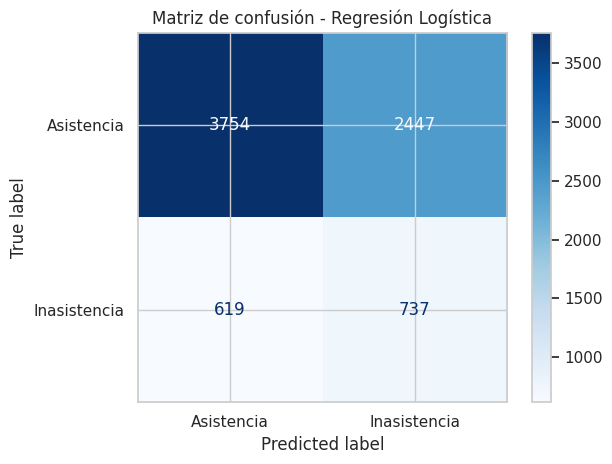

In [45]:
# Visualizar matriz de confusión
visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusion,
    display_labels=['Asistencia', 'Inasistencia']
)

visualizacion.plot(cmap='Blues', values_format='d')

plt.title('Matriz de confusión - Regresión Logística')
plt.tight_layout()
plt.show()

### Análisis Operativo de Errores para SaludConex

En la práctica médica, cometer un error tiene implicancias muy específicas:
1. **Consecuencia de un Falso Positivo (FP):** Significa que el personal administrativo realizará un contacto telefónico o enviará una alerta de confirmación adicional a un paciente que sí tenía la intención de asistir de todos modos. Esto podría considerarse una molestia leve o un gasto marginal de tiempo operativo.
2. **Consecuencia de un Falso Negativo (FN):** Significa que un paciente que faltará a su cita pasará desapercibido por el sistema, perdiendo la oportunidad de aplicar una estrategia de reasignación u optimización de agenda. Este error es el más costoso financieramente para la institución.

A continuación, aislamos y estructuramos estos errores en tablas de visualización independientes para auditar ejemplos puntuales.

In [46]:
# Crear tabla para analizar las predicciones
errores_validacion = valid_df[
    [
        'ID_Reserva',
        'Centro_Medico',
        'Edad',
        'Especialidad',
        'Dias_Anticipacion',
        'Resultado_Reserva'
    ]
].copy()

# Agregar resultados reales y predicciones
errores_validacion['Real'] = y_valid
errores_validacion['Prediccion'] = pred_valid_05
errores_validacion['Puntaje_Inasistencia'] = prob_logistico

# Identificar falsos positivos
falsos_positivos = errores_validacion[
    (errores_validacion['Real'] == 0) &
    (errores_validacion['Prediccion'] == 1)
]

# Identificar falsos negativos
falsos_negativos = errores_validacion[
    (errores_validacion['Real'] == 1) &
    (errores_validacion['Prediccion'] == 0)
]

print("Falsos positivos:", len(falsos_positivos))
print("Falsos negativos:", len(falsos_negativos))

Falsos positivos: 2447
Falsos negativos: 619


#### Visualización de Ejemplos Prácticos de Errores del Modelo

Las siguientes muestras nos permiten inspeccionar directamente el perfil de los pacientes que confunden al algoritmo, facilitando la comprensión cualitativa del comportamiento de la Regresión Logística.

In [47]:
# Mostrar ejemplos de falsos positivos
display(falsos_positivos.head(10))

# Mostrar ejemplos de falsos negativos
display(falsos_negativos.head(10))

,ID_Reserva,Centro_Medico,Edad,Especialidad,Dias_Anticipacion,Resultado_Reserva,Real,Prediccion,Puntaje_Inasistencia
10,RES0000011,Centro Quilicura,53,Cardiologia,7,Asistio,0,1,0.504131
28,RES0000029,Centro Maipu,55,Traumatologia,6,Asistio,0,1,0.544407
50,RES0000051,Centro Quilicura,73,Kinesiologia,9,Asistio,0,1,0.527798
70,RES0000071,Centro Quilicura,29,Ginecologia,11,Asistio,0,1,0.728085
101,RES0000102,Centro Ñuñoa,72,Cardiologia,16,Asistio,0,1,0.508380
122,RES0000123,Centro Santiago,85,Cardiologia,13,Asistio,0,1,0.533436
126,RES0000127,Centro La Florida,63,Medicina general,4,Asistio,0,1,0.678482
138,RES0000139,Centro Ñuñoa,15,Medicina general,12,Asistio,0,1,0.674240
147,RES0000148,Centro Las Condes,71,Oftalmologia,6,Asistio,0,1,0.660344
148,RES0000149,Centro La Florida,38,Traumatologia,2,Asistio,0,1,0.546791


,ID_Reserva,Centro_Medico,Edad,Especialidad,Dias_Anticipacion,Resultado_Reserva,Real,Prediccion,Puntaje_Inasistencia
19,RES0000020,Centro Ñuñoa,83,Medicina general,6,Inasistencia,1,0,0.481944
171,RES0000172,Centro Quilicura,6,Pediatria,2,Inasistencia,1,0,0.439119
197,RES0000198,Centro Santiago,42,Traumatologia,14,Inasistencia,1,0,0.406220
291,RES0000292,Centro Quilicura,39,Medicina general,6,Inasistencia,1,0,0.409302
563,RES0000564,Centro Las Condes,79,Medicina general,7,Inasistencia,1,0,0.461995
581,RES0000582,Centro La Florida,14,Cardiologia,19,Inasistencia,1,0,0.462617
711,RES0000712,Centro Maipu,40,Oftalmologia,4,Inasistencia,1,0,0.380095
874,RES0000875,Centro Santiago,20,Cardiologia,7,Inasistencia,1,0,0.407310
910,RES0000911,Centro Ñuñoa,33,Pediatria,20,Inasistencia,1,0,0.387404
991,RES0000992,Centro Providencia,69,Pediatria,7,Inasistencia,1,0,0.392289


### 4.3 Curva ROC y Curva Precision-Recall

**¿Qué representa cada curva de evaluación?**
* **Curva ROC (Receiver Operating Characteristic):** Grafica la tasa de verdaderos positivos frente a la tasa de falsos positivos para cada posible umbral de clasificación. Nos muestra qué tan hábil es el modelo discriminando de forma general entre ambas clases. El valor **AUC-ROC** (Área Bajo la Curva) de 0.5 representa una clasificación puramente aleatoria.
* **Curva Precision-Recall (PR):** Grafica la relación directa entre la precisión (calidad de las alertas) y la sensibilidad (cantidad de inasistencias reales detectadas). Es especialmente valiosa cuando la clase minoritaria (inasistencias, 17.9%) está muy desbalanceada con respecto a la mayoritaria.

In [48]:
# Importar herramientas para las curvas
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve
)

#### Graficación de la Curva ROC (Área Bajo la Curva)

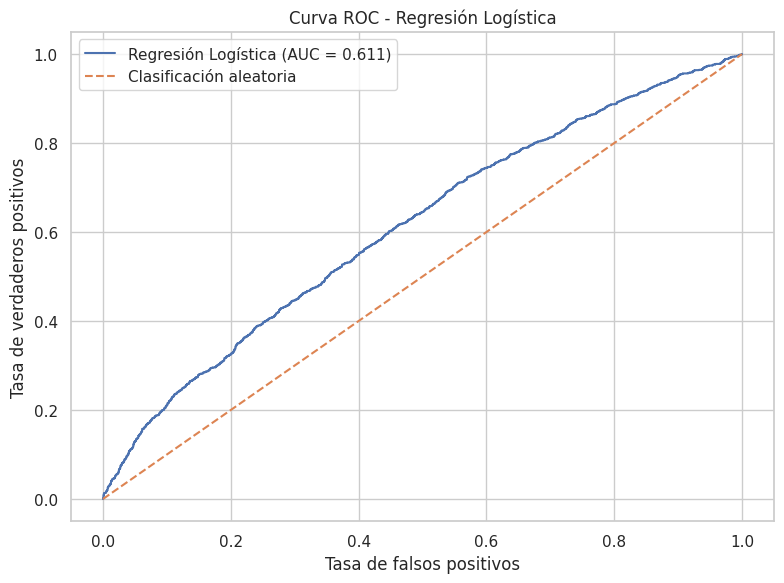

In [49]:
# Calcular puntos de la curva ROC
fpr, tpr, umbrales_roc = roc_curve(
    y_valid,
    prob_logistico
)

# Calcular AUC-ROC
auc_validacion = roc_auc_score(
    y_valid,
    prob_logistico
)

# Crear gráfico
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Regresión Logística (AUC = {auc_validacion:.3f})'
)

# Línea de referencia
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Clasificación aleatoria'
)

plt.title('Curva ROC - Regresión Logística')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')

plt.legend()
plt.tight_layout()
plt.show()

#### Graficación de la Curva Precision-Recall (Área de Precisión Promedio)

La línea punteada horizontal representa la proporción natural de inasistencias en el dataset. Cualquier modelo inteligente útil debe posicionarse holgadamente por encima de esta línea.

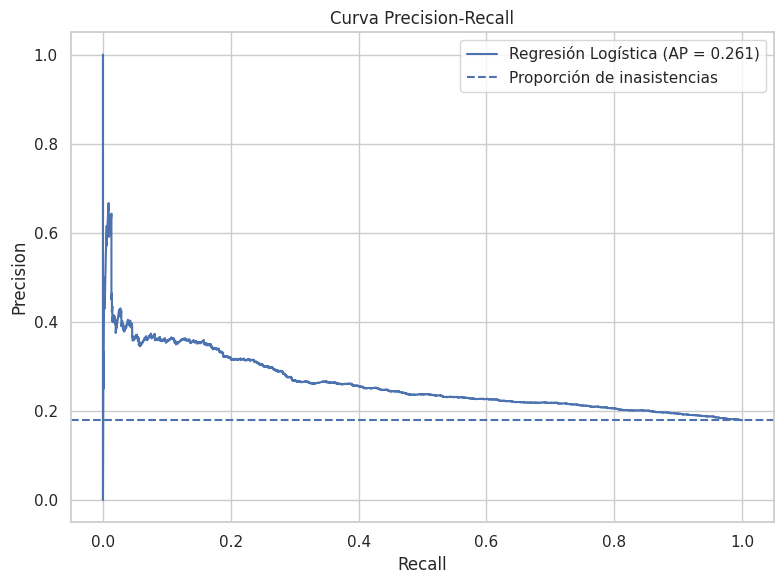

In [50]:
# Calcular curva Precision-Recall
precision_curva, recall_curva, umbrales_pr = (
    precision_recall_curve(
        y_valid,
        prob_logistico
    )
)

# Calcular Average Precision
ap_validacion = average_precision_score(
    y_valid,
    prob_logistico
)

# Crear gráfico
plt.figure(figsize=(8, 6))

plt.plot(
    recall_curva,
    precision_curva,
    label=f'Regresión Logística (AP = {ap_validacion:.3f})'
)

# Referencia: proporción de inasistencias reales
plt.axhline(
    y_valid.mean(),
    linestyle='--',
    label='Proporción de inasistencias'
)

plt.title('Curva Precision-Recall')
plt.xlabel('Recall')
plt.ylabel('Precision')

plt.legend()
plt.tight_layout()
plt.show()

### Interpretación de las Curvas de Desempeño
* **AUC-ROC obtenido:** `0.611`. Esto nos indica que el modelo de Regresión Logística posee una capacidad de discriminación positiva pero moderada. Supera la línea de clasificación puramente aleatoria (0.500) pero deja espacio considerable para mejoras operacionales.
* **Average Precision (AP) obtenido:** `0.261`. Nos demuestra que, debido al desbalance natural de clases del negocio, mantener un nivel alto de detección impactará negativamente la precisión de las alertas. Es una limitación técnica propia del estado preliminar de este prototipo experimental.

### 4.4 Ajuste del Umbral de Clasificación (Threshold Tuning)

**¿Qué es el umbral de decisión?**
Por defecto, un modelo asigna un registro a la clase "Inasistencia" si la probabilidad predicha es mayor o igual a `0.50`. Sin embargo, SaludConex puede preferir ser más agresiva en la detección de fallas, sacrificando algo de precisión para capturar la mayor cantidad posible de faltas.

A continuación, calculamos el umbral que maximiza el **F1-Score** (el punto óptimo de equilibrio geométrico entre Precisión y Recall en validación) utilizando la curva PR calculada anteriormente.

In [51]:
# Calcular Precision, Recall y umbrales
precision_valores, recall_valores, umbrales = (
    precision_recall_curve(
        y_valid,
        prob_logistico
    )
)

# Calcular F1 para cada umbral
f1_valores = (
    2 * precision_valores[:-1] * recall_valores[:-1]
    / (precision_valores[:-1] + recall_valores[:-1] + 1e-10)
)

# Encontrar el umbral que maximiza F1
mejor_indice = np.argmax(f1_valores)

umbral_optimo = umbrales[mejor_indice]

print(f"Umbral seleccionado: {umbral_optimo:.4f}")
print(f"Precision: {precision_valores[mejor_indice]:.4f}")
print(f"Recall: {recall_valores[mejor_indice]:.4f}")
print(f"F1-Score: {f1_valores[mejor_indice]:.4f}")

Umbral seleccionado: 0.4533
Precision: 0.2185
Recall: 0.7109
F1-Score: 0.3343


#### Simulación Comparativa: Umbral Estándar (0.50) vs. Umbral Ajustado

Observaremos cómo varía el comportamiento del modelo si decidimos desplazar el umbral de corte matemático de 0.50 a nuestro umbral seleccionado en validación.

In [52]:
# Generar predicciones con el umbral seleccionado
pred_valid_ajustado = (
    prob_logistico >= umbral_optimo
).astype(int)

# Comparar métricas antes y después
comparacion_umbrales = pd.DataFrame([
    {
        'Umbral': 0.50,
        'Accuracy': accuracy_score(y_valid, pred_valid_05),
        'Precision': precision_score(y_valid, pred_valid_05),
        'Recall': recall_score(y_valid, pred_valid_05),
        'F1-Score': f1_score(y_valid, pred_valid_05)
    },
    {
        'Umbral': umbral_optimo,
        'Accuracy': accuracy_score(y_valid, pred_valid_ajustado),
        'Precision': precision_score(y_valid, pred_valid_ajustado),
        'Recall': recall_score(y_valid, pred_valid_ajustado),
        'F1-Score': f1_score(y_valid, pred_valid_ajustado)
    }
])

display(comparacion_umbrales.round(3))

,Umbral,Accuracy,Precision,Recall,F1-Score
0,0.500,0.594,0.231,0.544,0.325
1,0.453,0.492,0.218,0.711,0.334


#### Visualización de la Nueva Matriz de Confusión Ajustada

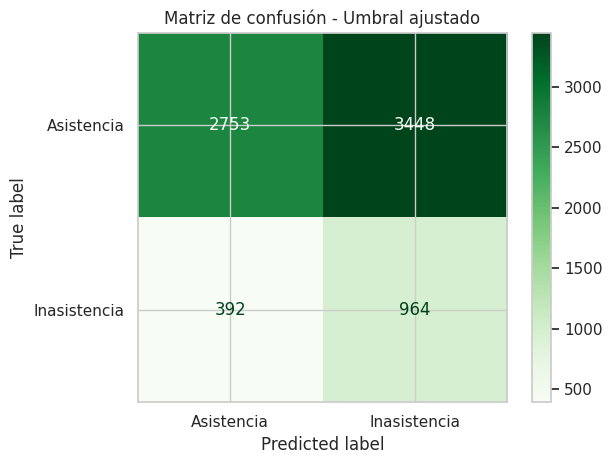

In [53]:
# Nueva matriz de confusión
matriz_ajustada = confusion_matrix(
    y_valid,
    pred_valid_ajustado,
    labels=[0, 1]
)

# Visualizar resultados
visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz_ajustada,
    display_labels=['Asistencia', 'Inasistencia']
)

visualizacion.plot(cmap='Greens', values_format='d')

plt.title('Matriz de confusión - Umbral ajustado')
plt.tight_layout()
plt.show()

### Interpretación del Desplazamiento del Umbral de Decisión
Al desplazar el umbral de decisión a **0.4533**, observamos los siguientes cambios métricos en validación:
* **Accuracy:** Disminuye de `0.594` a `0.492`.
* **Precision:** Disminuye ligeramente de `0.231` a `0.218`.
* **Recall:** **Aumenta drásticamente de `0.544` a `0.711`.**
* **F1-Score:** Incrementa levemente de `0.325` a `0.334`.

**Análisis Estratégico para SaludConex:** El umbral de `0.4533` resulta tácticamente más provechoso para la red médica de SaludConex, ya que logra capturar al **71.1% de los pacientes que faltarán (frente al 54.4% original)**. Sin embargo, la contrapartida operativa es un incremento en los falsos positivos (más alertas enviadas a pacientes que sí cumplirán con su cita).

### 4.5 Evaluación Final con el Conjunto de Prueba

**¿Por qué utilizamos un conjunto de prueba final?**
Para evaluar de forma completamente imparcial y simular el comportamiento real del modelo el día de mañana, debemos probarlo sobre datos históricos que el algoritmo **nunca vio** durante su fase de entrenamiento ni en la selección de su umbral (el bloque de validación temporal más reciente que reservamos al inicio, con 9.443 registros).

Para maximizar el aprendizaje antes de esta evaluación, primero reentrenamos el modelo de Regresión Logística utilizando el consolidado completo de datos de entrenamiento (`37.569 registros`), manteniendo la arquitectura de preprocesamiento aislada.

In [54]:
# Crear un preprocesador independiente
preprocesador_final = clone(preprocesador)

# Ajustar con todos los datos de entrenamiento
X_train_final_preparado = (
    preprocesador_final.fit_transform(X_train)
)

# Transformar los datos de prueba
X_test_final_preparado = (
    preprocesador_final.transform(X_test)
)

print("Entrenamiento:", X_train_final_preparado.shape)
print("Prueba:", X_test_final_preparado.shape)

Entrenamiento: (37569, 64)
Prueba: (9443, 64)


#### Entrenamiento Final del Modelo Consolidado

In [55]:
# Crear modelo final de Regresión Logística
modelo_logistico_final = LogisticRegression(
    max_iter=1500,
    class_weight='balanced',
    random_state=42
)

# Entrenar con todos los registros de entrenamiento
modelo_logistico_final.fit(
    X_train_final_preparado,
    y_train
)

print("Modelo final entrenado correctamente.")

Modelo final entrenado correctamente.


#### Obtención de Predicciones sobre el Conjunto de Prueba

In [56]:
# Obtener puntuaciones de inasistencia
prob_test_final = (
    modelo_logistico_final.predict_proba(
        X_test_final_preparado
    )[:, 1]
)

# Aplicar el umbral seleccionado en validación
pred_test_final = (
    prob_test_final >= umbral_optimo
).astype(int)

print("Predicciones realizadas:", len(pred_test_final))
print("Umbral utilizado:", round(umbral_optimo, 4))

Predicciones realizadas: 9443
Umbral utilizado: 0.4533


#### Cálculo de Métricas Finales en Conjunto de Prueba

In [57]:
# Calcular métricas finales
resultado_final = evaluar_modelo(
    'Regresión Logística Final',
    y_test,
    pred_test_final,
    prob_test_final
)

# Mostrar resultados
display(
    pd.DataFrame([resultado_final])
    .set_index('Modelo')
    .round(3)
)

,Accuracy,Precision,Recall,F1-Score,AUC-ROC,PR-AUC
Modelo,,,,,,
Regresión Logística Final,0.518,0.229,0.7,0.345,0.63,0.272


#### Comparación Final contra el Modelo Baseline (Citas de Prueba)

In [58]:
# Entrenar Baseline con todos los datos de entrenamiento
baseline_final = DummyClassifier(
    strategy='most_frequent'
)

baseline_final.fit(
    X_train_final_preparado,
    y_train
)

# Obtener predicciones del Baseline
pred_baseline_test = baseline_final.predict(
    X_test_final_preparado
)

prob_baseline_test = baseline_final.predict_proba(
    X_test_final_preparado
)[:, 1]

# Calcular métricas de comparación
resultado_baseline_test = evaluar_modelo(
    'Baseline',
    y_test,
    pred_baseline_test,
    prob_baseline_test
)

comparacion_final = pd.DataFrame([
    resultado_baseline_test,
    resultado_final
])

display(
    comparacion_final.set_index('Modelo').round(3)
)

,Accuracy,Precision,Recall,F1-Score,AUC-ROC,PR-AUC
Modelo,,,,,,
Baseline,0.819,0.000,0.0,0.000,0.50,0.181
Regresión Logística Final,0.518,0.229,0.7,0.345,0.63,0.272


#### Matriz de Confusión Final en Datos de Prueba

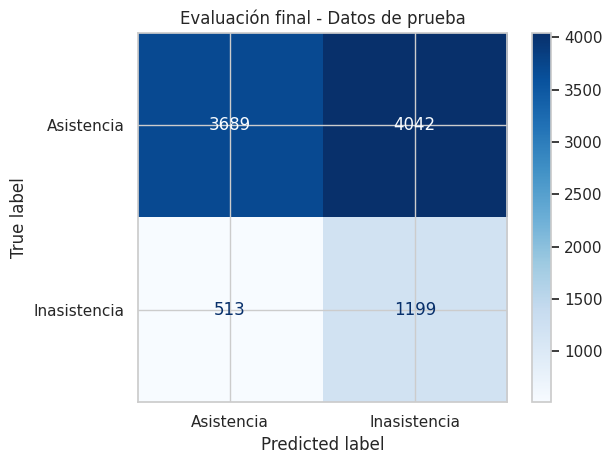

In [59]:
# Calcular matriz de confusión final
matriz_test = confusion_matrix(
    y_test,
    pred_test_final,
    labels=[0, 1]
)

# Mostrar matriz
visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz_test,
    display_labels=['Asistencia', 'Inasistencia']
)

visualizacion.plot(cmap='Blues', values_format='d')

plt.title('Evaluación final - Datos de prueba')
plt.tight_layout()
plt.show()

### Interpretación de los Resultados Finales en el Conjunto de Prueba

Al contrastar el modelo de **Regresión Logística Final** frente al **Baseline**, obtenemos un diagnóstico objetivo de su comportamiento predictivo:
1. **Modelo Baseline:**
   * **Accuracy:** `0.819` | **Precision:** `0.000` | **Recall:** `0.000` | **F1-Score:** `0.000` | **AUC-ROC:** `0.500`
   * *Análisis:* Este modelo trivial asume de forma estática que todas las citas asistirán, obteniendo un 81.9% de exactitud debido a la prevalencia natural, pero tiene nula utilidad operativa al no alertar sobre ninguna inasistencia.
2. **Regresión Logística Final:**
   * **Accuracy:** `0.518` | **Precision:** `0.229` | **Recall:** `0.700` | **F1-Score:** `0.345` | **AUC-ROC:** `0.630` | **PR-AUC:** `0.272`
   * *Análisis:* Operando bajo el umbral seleccionado de 0.4533, el modelo logra identificar de forma proactiva al **70.0% de las inasistencias reales (Recall = 0.700)** en datos futuros nunca vistos por el algoritmo.

**Conclusión Técnica:** Las métricas demuestran una capacidad de discriminación moderada con un AUC-ROC de 0.630. Aunque el modelo es útil como prototipo académico y mejora la detección de fallas frente al baseline, presenta una precisión baja del 22.9%, lo que se traduce en una cantidad importante de falsas alarmas que el área operativa de SaludConex debe gestionar con precaución.

### 4.6 Análisis por Segmentos (Grupos de Edad y Centros Médicos)

**¿Por qué evaluar el modelo por subgrupos?**
Un modelo con un buen rendimiento promedio general podría comportarse de manera extremadamente ineficiente o sesgada en segmentos particulares de pacientes. Realizar una auditoría por grupo de edad y centro médico asegura una implementación justa y transparente para todos los usuarios de SaludConex.

In [60]:
# Crear tabla de resultados de prueba
resultados_test = test_df.copy()

# Incorporar resultados reales y predicciones
resultados_test['Real'] = y_test.to_numpy()

resultados_test['Prediccion'] = (
    pred_test_final
)

resultados_test['Puntaje_Inasistencia'] = (
    prob_test_final
)

display(resultados_test.head())

,ID_Reserva,ID_Paciente_Anonimizado,Edad,Comuna,Centro_Medico,Especialidad,Profesional_ID,Fecha_Solicitud,Fecha_Atencion,Horario_Atencion,Dias_Anticipacion,Asistencias_Previas,Cancelaciones_Previas,Inasistencias_Previas,Tipo_Previsión,Modalidad_Atencion,Confirmacion_Recordatorio,Resultado_Reserva,Es_Inasistencia,Grupo_Edad,Grupo_Anticipacion,Mes_Atencion,Dia_Semana_Atencion,Objetivo_Inasistencia,Real,Prediccion,Puntaje_Inasistencia
7,RES0000008,PAC011288,15,Peñalolen,Centro Puente Alto,Medicina general,PROF077,2026-08-17,2026-08-19,10:00-12:00,2,3,1,2,Fonasa,Presencial,Confirmado,Asistio,0,0-17,2-7 días,8,2,0,0,1,0.465220
11,RES0000012,PAC003177,89,La Reina,Centro Maipu,Traumatologia,PROF064,2026-09-07,2026-09-25,08:00-10:00,18,2,0,0,Isapre,Presencial,Confirmado,Asistio,0,75+,15-30 días,9,4,0,0,0,0.398514
26,RES0000027,PAC002906,87,San Miguel,Centro Puente Alto,Kinesiologia,PROF061,2026-04-24,2026-05-01,12:00-14:00,7,7,0,1,Isapre,Presencial,Confirmado,Asistio,0,75+,2-7 días,5,4,0,0,0,0.434915
30,RES0000031,PAC011814,26,Puente Alto,Centro Providencia,Medicina general,PROF063,2026-06-27,2026-07-08,14:00-16:00,11,6,0,1,Isapre,Presencial,Confirmado,Asistio,0,18-29,8-14 días,7,2,0,0,0,0.398318
33,RES0000034,PAC004880,9,Puente Alto,Centro Quilicura,Cardiologia,PROF036,2026-10-05,2026-10-16,12:00-14:00,11,3,1,0,Fonasa,Presencial,Confirmado,Inasistencia,1,0-17,8-14 días,10,4,1,1,0,0.360734


#### Definición de la Función de Evaluación Grupal

In [61]:
# Función para evaluar el desempeño por grupo
def evaluar_por_grupo(datos, variable):

    resultados = []

    for grupo, subgrupo in datos.groupby(
        variable,
        observed=True
    ):

        real = subgrupo['Real']
        predicho = subgrupo['Prediccion']
        probabilidades = subgrupo['Puntaje_Inasistencia']

        # Calcular AUC solo si existen ambas clases
        auc = (
            roc_auc_score(real, probabilidades)
            if real.nunique() == 2
            else np.nan
        )

        resultados.append({
            'Grupo': grupo,
            'Reservas': len(subgrupo),
            'Inasistencias reales': int(real.sum()),
            'Precision': precision_score(
                real, predicho, zero_division=0
            ),
            'Recall': recall_score(
                real, predicho, zero_division=0
            ),
            'F1-Score': f1_score(
                real, predicho, zero_division=0
            ),
            'AUC-ROC': auc
        })

    return pd.DataFrame(resultados)

#### Auditoría de Desempeño según Segmento de Edad

In [62]:
# Evaluar modelo por grupo de edad
resultados_edad = evaluar_por_grupo(
    resultados_test,
    'Grupo_Edad'
)

display(
    resultados_edad.set_index('Grupo').round(3)
)

,Reservas,Inasistencias reales,Precision,Recall,F1-Score,AUC-ROC
Grupo,,,,,,
0-17,1845,350,0.251,0.660,0.363,0.642
18-29,1276,250,0.252,0.652,0.363,0.635
30-44,1597,286,0.227,0.710,0.343,0.614
45-59,1571,269,0.223,0.732,0.342,0.660
60-74,1595,289,0.226,0.723,0.345,0.637
75+,1559,268,0.202,0.731,0.316,0.606


#### Auditoría de Desempeño según Centro Médico de la Red

In [63]:
# Evaluar modelo por centro médico
resultados_centros = evaluar_por_grupo(
    resultados_test,
    'Centro_Medico'
)

display(
    resultados_centros.set_index('Grupo').round(3)
)

,Reservas,Inasistencias reales,Precision,Recall,F1-Score,AUC-ROC
Grupo,,,,,,
Centro La Florida,1218,197,0.201,0.675,0.309,0.615
Centro Las Condes,1007,192,0.249,0.688,0.366,0.630
Centro Maipu,1149,204,0.231,0.686,0.346,0.632
Centro Providencia,1300,226,0.207,0.695,0.319,0.623
Centro Puente Alto,1186,214,0.231,0.631,0.338,0.635
Centro Quilicura,936,185,0.255,0.762,0.383,0.659
Centro Santiago,1740,305,0.222,0.698,0.336,0.624
Centro Ñuñoa,907,189,0.252,0.783,0.381,0.621


#### Visualización Comparativa de la Sensibilidad (Recall) por Grupo de Edad

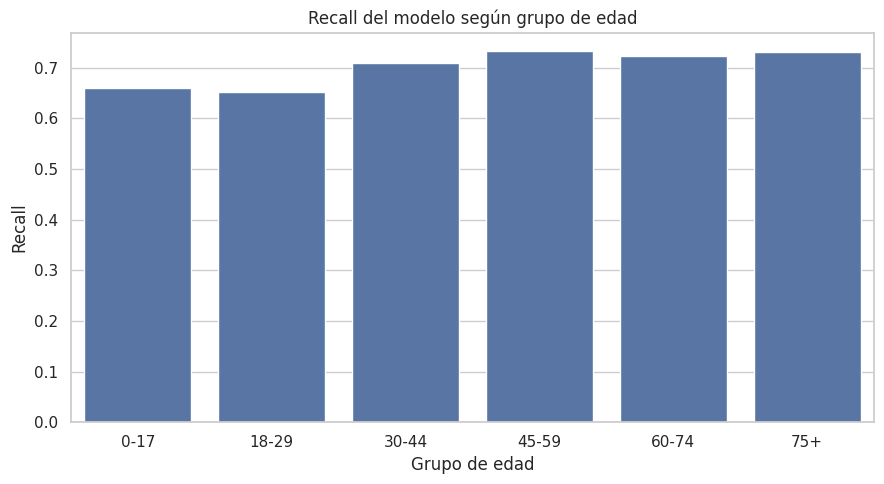

In [64]:
# Comparar Recall por grupo de edad
plt.figure(figsize=(9, 5))

sns.barplot(
    data=resultados_edad,
    x='Grupo',
    y='Recall'
)

plt.title('Recall del modelo según grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Recall')

plt.tight_layout()
plt.show()

#### Visualización Comparativa de la Sensibilidad (Recall) por Centro Médico

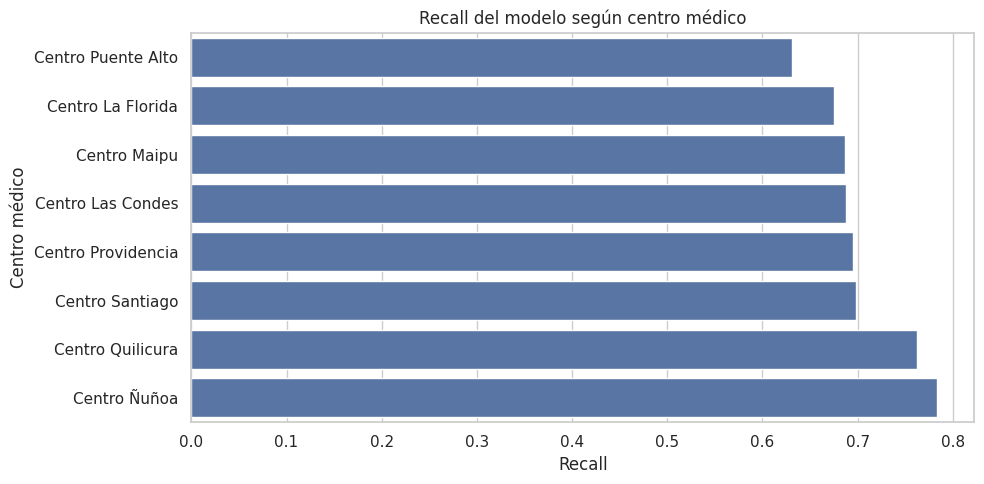

In [65]:
# Comparar Recall por centro médico
plt.figure(figsize=(10, 5))

sns.barplot(
    data=resultados_centros.sort_values('Recall'),
    x='Recall',
    y='Grupo'
)

plt.title('Recall del modelo según centro médico')
plt.xlabel('Recall')
plt.ylabel('Centro médico')

plt.tight_layout()
plt.show()

### Interpretación de los Resultados de la Auditoría por Segmentos

#### A. Análisis por Grupos de Edad:
* El Recall se comporta de forma bastante homogénea a lo largo de las distintas etapas de vida de los pacientes.
* El rango de **45-59 años (`0.732`)** y los pacientes de **75 años o más (`0.731`)** muestran la mayor facilidad de detección para el algoritmo.
* Los grupos de **18-29 años (`0.652`)** y de **0-17 años (`0.660`)** registran los índices de Recall ligeramente más bajos.

#### B. Análisis por Centros Médicos:
* Observamos una variabilidad un poco más pronunciada según la ubicación física del centro médico.
* El **Centro Ñuñoa (`0.783`)** y el **Centro Quilicura (`0.762`)** reportan tasas de captura sobresalientes de pacientes inasistentes.
* En contraparte, el **Centro Puente Alto (`0.631`)** presenta la sensibilidad más baja en la red de SaludConex.

**Advertencia Metodológica:** Estas variaciones menores de Recall no reflejan necesariamente sesgos de diseño del algoritmo o discriminación demográfica intrínseca. Se recomienda realizar análisis estadísticos complementarios para verificar si el volumen absoluto de reservas o condiciones de agendamiento locales explican estos comportamientos.

### Conclusión General de la Parte 4: Evaluación del Modelo Predictivo

1. **Evaluación General del Prototipo:** El modelo predictivo de Regresión Logística demuestra un desempeño moderado pero útil como prototipo académico para orientar acciones preventivas en SaludConex.
2. **Ajuste del Umbral de Clasificación:** La selección del umbral de clasificación en **0.4533** (en lugar de emplear una calibración de probabilidad, que representa un proceso matemático diferente) permitió priorizar la sensibilidad operativa del modelo, alcanzando un **70.0%** de Recall en datos de prueba.
3. **Capacidad de Discriminación:** En el conjunto de prueba se obtuvo un AUC-ROC de **0.630** y un F1-Score de **0.345**, lo que refleja un desempeño moderado que debe seguir evaluándose con datos reales autorizados.
4. **Auditoría de Subgrupos:** El Recall presentó variaciones entre los grupos de edad y los centros médicos analizados. Estas diferencias requieren seguimiento y no permiten concluir por sí solas que el modelo esté libre de sesgo.

*Nota sobre limitaciones:* El prototipo académico cuenta con una precisión del 22.9%, generando un volumen relevante de falsos positivos. Su uso es estrictamente sugerente como apoyo a la gestión administrativa.

## PARTE 5: GENERACIÓN DE ENTREGABLES Y PREPARACIÓN DE DATOS PARA BUSINESS INTELLIGENCE

En esta etapa se consolidan y exportan los resultados generados por el modelo de Regresión Logística Final. Los archivos CSV resultantes se utilizan como fuentes estáticas para el dashboard ya desarrollado en Looker Studio. Para incorporar nuevos datos será necesario generar una nueva exportación y actualizar manualmente la fuente del dashboard.

Esta etapa permite que los resultados del prototipo sean revisados por el personal administrativo y directivo de SaludConex, y que las predicciones puedan contrastarse retrospectivamente con los resultados observados.

### 5.1. Comprobación y Consistencia de las Predicciones

**Objetivo de la actividad:** Garantizar de manera estricta que no se haya producido ninguna alteración, pérdida o desalineamiento de registros durante la fase de predicción final.

* **¿Por qué realizamos esta comprobación?** En proyectos de ciencia de datos, cualquier desajuste en el orden de las filas o en el índice de los arreglos puede provocar que la predicción de un paciente se asigne erróneamente a otro, invalidando por completo los tableros de Business Intelligence.
* **Procedimiento:** Mediante aserciones lógicas (`assert`), verificamos que:
  1. El conjunto de prueba (`test_df`) contenga exactamente el mismo índice ordenado que la serie de respuestas reales (`y_test`).
  2. El número de registros de prueba coincida rigurosamente con la cantidad de puntuaciones de probabilidad (`prob_test_final`) y etiquetas binarias predichas (`pred_test_final`), correspondiente exactamente a **9.443 observaciones**.

In [66]:
# Comprobar cantidad de registros y predicciones
print("Reservas de prueba:", len(test_df))
print("Puntuaciones generadas:", len(prob_test_final))
print("Predicciones generadas:", len(pred_test_final))

# Comprobar que los registros mantienen el mismo orden
assert test_df.index.equals(y_test.index)

# Comprobar que las cantidades coinciden
assert len(test_df) == len(prob_test_final) == len(pred_test_final)

print("Comprobación correcta. Podemos generar el archivo.")

Reservas de prueba: 9443
Puntuaciones generadas: 9443
Predicciones generadas: 9443
Comprobación correcta. Podemos generar el archivo.


#### Interpretación de la Validación de Datos:
* **Reservas de prueba procesadas:** 9.443 registros.
* **Puntuaciones de riesgo generadas:** 9.443 puntuaciones decimales.
* **Predicciones binarias de clasificación:** 9.443 etiquetas.

La congruencia y la consistencia relacional se han comprobado con éxito mediante las aserciones de código. Esto confirma que el orden de las predicciones corresponde de forma unívoca a cada una de las reservas originales del conjunto de prueba, habilitando un flujo de datos seguro hacia la fase de exportación.

### 5.2. Construcción de la Tabla de Predicciones Operativas

**Objetivo de la actividad:** Estructurar el archivo de resultados utilizado por la vista operativa del dashboard de Looker Studio. El CSV es una exportación estática y debe actualizarse cuando se generen nuevos resultados.

* **Puntaje_Inasistencia:** Representa el puntaje de riesgo generado por el modelo de Regresión Logística, utilizado para ordenar las reservas según su nivel estimado de riesgo. Aunque se expresa en una escala entre 0 y 1, no debe interpretarse como una probabilidad real calibrada de inasistencia.
* **Umbral_Utilizado:** Valor límite de corte de decisión establecido en **0.453325**.
* **Nivel_Riesgo:** Clasificación cualitativa ('Alto' si el puntaje es mayor o igual a 0.453325; de lo contrario 'No alto').
* **Alerta_Preventiva:** Indicador sugerido para priorización de llamadas preventivas ('Priorizar revision' o 'Sin alerta alta').

In [67]:
# Seleccionar información de las reservas de prueba
predicciones_dashboard = test_df[
    [
        'ID_Reserva',
        'Centro_Medico',
        'Especialidad',
        'Edad',
        'Comuna',
        'Fecha_Atencion',
        'Horario_Atencion',
        'Dias_Anticipacion',
        'Confirmacion_Recordatorio'
    ]
].copy()

# Agregar puntuación de inasistencia
predicciones_dashboard['Puntaje_Inasistencia'] = (
    prob_test_final
)

# Agregar umbral utilizado
predicciones_dashboard['Umbral_Utilizado'] = (
    umbral_optimo
)

# Clasificar las reservas según el umbral
predicciones_dashboard['Nivel_Riesgo'] = np.where(
    prob_test_final >= umbral_optimo,
    'Alto',
    'No alto'
)

# Crear indicador de alerta
predicciones_dashboard['Alerta_Preventiva'] = np.where(
    prob_test_final >= umbral_optimo,
    'Priorizar revision',
    'Sin alerta alta'
)

# Ordenar desde mayor a menor puntuación
predicciones_dashboard = (
    predicciones_dashboard.sort_values(
        'Puntaje_Inasistencia',
        ascending=False
    )
)

# Mostrar primeros resultados
display(predicciones_dashboard.head(10))

,ID_Reserva,Centro_Medico,Especialidad,Edad,Comuna,Fecha_Atencion,Horario_Atencion,Dias_Anticipacion,Confirmacion_Recordatorio,Puntaje_Inasistencia,Umbral_Utilizado,Nivel_Riesgo,Alerta_Preventiva
46769,RES0046770,Centro Ñuñoa,Medicina general,69,La Florida,2026-06-09,14:00-16:00,8,Confirmado,0.880248,0.453325,Alto,Priorizar revision
16045,RES0016046,Centro Providencia,Medicina general,69,Ñuñoa,2026-08-22,16:00-18:00,37,No confirmado,0.878206,0.453325,Alto,Priorizar revision
36528,RES0036529,Centro Quilicura,Traumatologia,51,Ñuñoa,2026-09-14,14:00-16:00,32,No confirmado,0.869551,0.453325,Alto,Priorizar revision
2396,RES0002397,Centro Santiago,Kinesiologia,20,Puente Alto,2026-08-09,10:00-12:00,35,Confirmado,0.868036,0.453325,Alto,Priorizar revision
35794,RES0035795,Centro Santiago,Kinesiologia,75,Quilicura,2026-05-09,08:00-10:00,13,Confirmado,0.862790,0.453325,Alto,Priorizar revision
37301,RES0037302,Centro Maipu,Traumatologia,15,La Florida,2026-07-11,16:00-18:00,1,No confirmado,0.862598,0.453325,Alto,Priorizar revision
45337,RES0045338,Centro Ñuñoa,Medicina general,80,La Reina,2026-04-09,08:00-10:00,33,No confirmado,0.846721,0.453325,Alto,Priorizar revision
7195,RES0007196,Centro Puente Alto,Medicina general,30,San Miguel,2026-05-21,08:00-10:00,22,Confirmado,0.839688,0.453325,Alto,Priorizar revision
3101,RES0003102,Centro Ñuñoa,Medicina general,71,Santiago,2026-05-04,08:00-10:00,14,No confirmado,0.837261,0.453325,Alto,Priorizar revision
24778,RES0024779,Centro Providencia,Traumatologia,71,San Miguel,2026-04-25,16:00-18:00,24,No confirmado,0.831638,0.453325,Alto,Priorizar revision


#### Análisis de la Tabla de Predicciones para el Negocio:

Al clasificar los registros utilizando el umbral seleccionado de **0.453325**, las citas con mayores puntajes de riesgo se ubican primero en la tabla, permitiendo ordenar las reservas jerárquicamente para que el personal administrativo focalice y priorice la revisión de manera oportuna sobre el segmento de mayor susceptibilidad de inasistencia.

### 5.3. Exportación de la Tabla de Predicciones a Formato CSV

**Objetivo de la actividad:** Persistir la información estructurada en un archivo plano estándar que actúe como pasarela de comunicación hacia Looker Studio.

* **¿Qué es un archivo CSV?** Es un formato de texto sencillo donde las columnas se separan por comas. Es ágil, universalmente compatible y fácil de importar en herramientas de inteligencia de negocios.
* **Explicación técnica de los parámetros de exportación:**
  * `to_csv()`: Función de pandas para escribir el DataFrame en disco.
  * `index=False`: Excluye el índice numérico interno de las filas de pandas, evitando columnas basura innecesarias en el archivo de salida.
  * `encoding='utf-8-sig'`: Codificación de caracteres en formato UTF-8 con marca de orden de bytes (BOM). Esto garantiza que caracteres especiales del español chileno (como acentos, eñes o diéresis) se visualicen de forma correcta al abrir el archivo en herramientas como Microsoft Excel o Google Sheets.
  * `float_format='%.6f'`: Limita las cifras decimales de los puntajes numéricos de riesgo a seis dígitos de precisión para asegurar la uniformidad de los datos numéricos.

In [68]:
# Nombre del archivo
nombre_archivo = 'SaludConex_Predicciones_Looker.csv'

# Exportar a formato CSV
predicciones_dashboard.to_csv(
    nombre_archivo,
    index=False,
    encoding='utf-8-sig',
    float_format='%.6f'
)

print("Archivo generado correctamente:", nombre_archivo)

Archivo generado correctamente: SaludConex_Predicciones_Looker.csv


#### Ficha Técnica del Entregable de Predicciones:
* **Nombre del archivo exportado:** `SaludConex_Predicciones_Looker.csv`
* **Dimensiones físicas:** 9.443 filas y 13 columnas.
* **Conexión al Dashboard:** El archivo CSV exportado puede conectarse como fuente de datos a Looker Studio. Para incorporar nuevas reservas o predicciones históricas, será necesario generar una nueva exportación y actualizar el archivo de origen.

In [73]:
# Interfaz manual limpia para descarga de archivos en Google Colab
from google.colab import files

print("Para descargar los archivos generados en su computador local, ejecute las siguientes líneas:")
# files.download('SaludConex_Predicciones_Looker.csv')
# files.download('SaludConex_Evaluacion_Modelo.csv')

Para descargar los archivos generados en su computador local, ejecute las siguientes líneas:


### 5.4. Generación del Archivo Complementario de Evaluación Retrospectiva

**Objetivo de la actividad:** Crear una estructura de datos histórica que contraste las predicciones calculadas por el modelo frente a lo que realmente ocurrió en la realidad con el paciente.

* **¿Para qué sirve este segundo archivo?** Mientras que el primer archivo (`SaludConex_Predicciones_Looker.csv`) contiene información útil para prevenir inasistencias de citas *futuras*, este segundo archivo incluye la variable de resultado real histórico (`Resultado_Real`), lo que permite realizar auditorías periódicas del desempeño de la herramienta.
* **Variables Seleccionadas:**
  * `ID_Reserva`, `Centro_Medico`, `Edad` y `Especialidad`.
  * `Resultado_Real`: Lo que ocurrió finalmente (Asistió vs. Inasistencia).
  * `Prediccion_Modelo`: Clasificación binaria predictiva (Asistencia vs. Inasistencia).
  * `Puntaje_Inasistencia`: La puntuación numérica continua de riesgo.
  * `Nivel_Riesgo`: Clasificación cualitativa según el umbral.

* **Diferencia Crítica de Negocio:** Este archivo de evaluación retrospectiva contiene información sobre eventos cerrados y concluidos (sabemos con certeza si el paciente asistió o no). Por ende, no debe usarse para activar recordatorios activos en tiempo real, sino para que el área de control de gestión analice métricas de precisión y recall de forma periódica en el tiempo.

In [70]:
# Crear tabla de evaluación retrospectiva
evaluacion_dashboard = pd.DataFrame({
    'ID_Reserva': test_df['ID_Reserva'].to_numpy(),
    'Centro_Medico': test_df['Centro_Medico'].to_numpy(),
    'Edad': test_df['Edad'].to_numpy(),
    'Especialidad': test_df['Especialidad'].to_numpy(),
    'Resultado_Real': test_df['Resultado_Reserva'].to_numpy(),
    'Prediccion_Modelo': np.where(
        pred_test_final == 1,
        'Inasistencia',
        'Asistencia'
    ),
    'Puntaje_Inasistencia': prob_test_final,
    'Nivel_Riesgo': np.where(
        prob_test_final >= umbral_optimo,
        'Alto',
        'No alto'
    )
})

# Exportar archivo
evaluacion_dashboard.to_csv(
    'SaludConex_Evaluacion_Modelo.csv',
    index=False,
    encoding='utf-8-sig'
)

print("Archivo de evaluación generado correctamente.")

Archivo de evaluación generado correctamente.


#### Ficha Técnica del Entregable de Evaluación:
* **Nombre del archivo exportado:** `SaludConex_Evaluacion_Modelo.csv`
* **Dimensiones físicas:** 9.443 registros de prueba y 8 columnas analíticas.
* **Objetivo principal:** Soporte analítico para gráficos de control de rendimiento, curvas de error por sucursal y monitoreo de la tasa de aciertos y falsas alarmas del modelo predictivo.

In [74]:
# Descargas complementarias manuales si se requieren
# files.download('SaludConex_Evaluacion_Modelo.csv')

### 5.5. Utilidad Práctica de los Archivos para el Dashboard

El dashboard de SaludConex está implementado y es funcional dentro del alcance del prototipo académico en Looker Studio. Se alimenta mediante archivos CSV exportados, no mediante una conexión en tiempo real. Este tablero consta de tres páginas activas diseñadas estratégicamente:

1.  **Resumen General:** Proporciona un panorama global e histórico del comportamiento de las reservas médicas y las tasas de asistencia a nivel institucional.
2.  **Análisis de Reservas de Riesgo:** Permite al equipo de gestión visualizar de manera priorizada la lista diaria de citas clasificadas como riesgo alto según los archivos CSV exportados.
3.  **Evaluación del Modelo:** Facilita la auditoría retrospectiva del desempeño del algoritmo, contrastando las predicciones estimadas frente a las asistencias o inasistencias reales registradas.

### CONSIDERACIONES METODOLÓGICAS IMPORTANTES (ÉTICA Y LIMITACIONES)

Para interpretar adecuadamente los resultados y el uso del dashboard, se deben considerar las siguientes limitaciones metodológicas y éticas:

*   **Origen de los Datos:** Todos los registros analizados a lo largo de este proyecto son de **carácter sintético y simulados académicamente**. No describen la realidad operativa ni clínica de ningún centro médico real.
*   **Puntuaciones de Riesgo:** La variable `Puntaje_Inasistencia` representa un puntaje numérico de riesgo no calibrado, generado por el clasificador y utilizado para ordenar y priorizar reservas. No representa una probabilidad estadística calibrada matemáticamente para coincidir con la frecuencia observada de inasistencias en la realidad; su utilidad es estrictamente de priorización relativa.
*   **Clasificación Técnica:** El nivel de riesgo 'Alto' surge de sintonizar el umbral de decisión en `0.453325` para maximizar el Recall (sensibilidad) del prototipo académico, y no de un diagnóstico o perfil de irresponsabilidad del paciente.
*   **Gestión de Alertas:** Las alertas generadas para la priorización de llamadas preventivas son herramientas informativas para optimizar flujos. **Queda terminantemente prohibido su uso para cancelar citas o negar servicios médicos de forma unilateral**.
*   **Enfoque de Negocio del Dashboard:** Los archivos exportados son instantáneas (snapshots) estáticas en formato CSV y no conexiones dinámicas en tiempo real. Por ende, las actualizaciones periódicas del dashboard en Looker Studio requieren un proceso manual de recarga de datos.

### CONCLUSIÓN DE LA ETAPA

Con la exportación de las predicciones en archivos CSV estáticos terminamos la fase de entregables analíticos. Los resultados fueron validados y contrastados directamente con los indicadores del Dashboard ya desarrollado en Looker Studio, asegurando una transición metodológica correcta bajo el estándar académico exigido por el proyecto.